# 07 - Threshold Analysis, Explainability and Feature-Group Ablation (Phase 6)
**Provisional model:** logistic regression with categorical counts (`LR_B`, L2, C = 1), raw (uncalibrated) probabilities - exactly the Phase 4 artifact, as confirmed by Phase 5.

| Part | Question |
|---|---|
| A | How do accuracy, precision, recall, F1 and specificity change with the decision threshold, and what operating threshold is defensible? |
| B | Which features is the model's predicted odds associated with (coefficients, permutation importance)? |
| C | How can individual validation predictions be explained? |
| D | How much predictive information comes from each feature group (ablation)? |
| E | Where does the model make confident mistakes, and what does that say about a performance ceiling? |

## Data policy (enforced in code)
| Split | Phase 6 use |
|---|---|
| TRAIN (`train.csv`, 6,938) | model/pipeline fitting, 5-fold CV for the ablation, coefficient confidence intervals |
| Phase 5 OOF probabilities (`06_oof_predictions.csv`) | honest training-side threshold analysis |
| VALIDATION (`validation.csv`, 1,487) | validation-side threshold analysis, permutation importance, individual explanations, ablation confirmation, error analysis |
| TEST (`test.csv`) | **off limits.** An audit hook *raises an error the moment any process-level `open()` touches a file named `test.csv`* (raw or processed); the notebook ends by printing every data file opened and asserting the test set was never accessed. |

*Disclosure:* the validation split already served model development (Phase 4 selection). A threshold chosen on validation, and then scored on validation, is therefore **optimistic**; the OOF analysis is the independent check. Nothing here is a causal statement: every explanation describes the *fitted model's associations* in observational (possibly rule-generated) data.

In [1]:
import warnings
warnings.simplefilter("always")
import os, sys, json, time
from pathlib import Path

# ---- TEST-SET AUDIT HOOK: record every file open; RAISE immediately if a file named test.csv is opened ----
_OPENED = []
def _audit(event, args):
    if event == "open" and args and isinstance(args[0], (str, bytes, os.PathLike)):
        p = os.fsdecode(args[0]); _OPENED.append(p)
        if os.path.basename(p).lower() == "test.csv":
            raise PermissionError(f"PHASE 6 VIOLATION: attempt to open {p} (the test set is off limits)")
sys.addaudithook(_audit)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn
import statsmodels.api as sm
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss, brier_score_loss)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, MODELS = ROOT / "data" / "processed", ROOT / "models" / "phase4"
MET, FIG = ROOT / "results" / "metrics" / "modeling", ROOT / "results" / "figures" / "modeling"
MET.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

SEED, K, B_BOOT = 42, 5, 1000
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_colwidth", 110)
sns.set_theme(style="whitegrid", rc={"grid.color": "#e3e6ea", "axes.edgecolor": "#9aa3ad", "axes.titlesize": 12,
                                      "axes.titleweight": "semibold", "axes.labelsize": 10.5, "figure.dpi": 110})
PLACED_C, NOT_C, NEUTRAL = "#2166ac", "#e08214", "#6b7785"
LR_C = "#0072B2"
def savefig(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight"); plt.show()
print("scikit-learn", sklearn.__version__, "| seed", SEED)

scikit-learn 1.9.1 | seed 42


## 1. Load TRAIN and VALIDATION only; load the fitted Phase 4 `LR_B`; reproduction checks

In [2]:
TARGET = "PlacementStatus"
FEATURES = ["CGPA", "Internships", "Projects", "Workshops/Certifications", "AptitudeTestScore", "SoftSkillsRating",
            "ExtracurricularActivities", "PlacementTraining", "SSC_Marks", "HSC_Marks"]
CONT = ["CGPA", "AptitudeTestScore", "SoftSkillsRating", "SSC_Marks", "HSC_Marks"]       # Phase 4 column order
COUNT = ["Internships", "Projects", "Workshops/Certifications"]
BIN = ["ExtracurricularActivities", "PlacementTraining"]
train = pd.read_csv(PROC / "train.csv"); val = pd.read_csv(PROC / "validation.csv")
for d in (train, val):
    assert d.isna().sum().sum() == 0 and set(d[TARGET]) == {"Placed", "NotPlaced"}
assert not (set(map(tuple, train[FEATURES].values)) & set(map(tuple, val[FEATURES].values)))
X_tr, X_va = train[FEATURES].copy(), val[FEATURES].copy()
y_tr = (train[TARGET] == "Placed").astype(int).to_numpy(); y_va = (val[TARGET] == "Placed").astype(int).to_numpy()
for c in COUNT: X_tr[c] = X_tr[c].astype(int); X_va[c] = X_va[c].astype(int)
BASE_RATE_TR, BASE_RATE_VA = y_tr.mean(), y_va.mean()
print(f"train {X_tr.shape} (Placed {BASE_RATE_TR:.4f}) | validation {X_va.shape} (Placed {BASE_RATE_VA:.4f})")

with open(MODELS / "model_configs.json", encoding="utf-8") as fh: P4 = json.load(fh)
REFS = {k: int(v) for k, v in P4["count_reference_levels_(LR)"].items()}          # fixed Phase 4 reference levels (train mode)
assert REFS == {c: int(X_tr[c].mode().iloc[0]) for c in COUNT}
LR = joblib.load(MODELS / "LR_B.joblib")                                           # already fitted on the full training set in Phase 4
pre, lrm = LR.named_steps["prep"], LR.named_steps["model"]
assert LR.get_params()["model__C"] == 1.0 and lrm.classes_.tolist() == [0, 1]

# (1) the loaded model reproduces the saved Phase 4 validation probabilities
p4 = pd.read_csv(MET / "05_validation_predictions.csv"); assert (p4.y_true.to_numpy() == y_va).all()
p_va = LR.predict_proba(X_va)[:, 1]; assert np.allclose(p_va, p4["LR_B"].to_numpy(), atol=1e-10)
# (2) Phase 5 OOF file: same row order/target as train.csv and the same fold assignment as StratifiedKFold(5, shuffle, 42)
oof = pd.read_csv(MET / "06_oof_predictions.csv")
assert (oof.train_row_id.to_numpy() == np.arange(len(train))).all() and (oof.actual_target.to_numpy() == y_tr).all()
outer = list(StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED).split(X_tr, y_tr))
fold_of = np.empty(len(y_tr), int)
for k, (_, te) in enumerate(outer, 1): fold_of[te] = k
assert (oof.fold.to_numpy() == fold_of).all()
p_oof = oof["logistic_probability"].to_numpy()
# (3) coefficients of the loaded object equal the Phase 4 coefficient table
c4 = pd.read_csv(MET / "05_logistic_coefficients.csv"); c4 = c4[(c4.model_id == "LR_B") & (c4.feature != "(intercept)")]
assert np.allclose(np.sort(c4.coefficient.to_numpy()), np.sort(lrm.coef_[0]), atol=1e-10)
print("Reproduction checks passed: Phase 4 validation probabilities, Phase 5 OOF rows/folds, Phase 4 coefficients.")
print("Count reference levels:", REFS, "| binary reference: 'No'")

train (6938, 10) (Placed 0.4155) | validation (1487, 10) (Placed 0.4156)


Reproduction checks passed: Phase 4 validation probabilities, Phase 5 OOF rows/folds, Phase 4 coefficients.
Count reference levels: {'Internships': 1, 'Projects': 3, 'Workshops/Certifications': 0} | binary reference: 'No'


## 2. Metric helpers
Classification rule everywhere: **predict Placed when `p >= threshold`** (as in Phases 4-5). The probability remains the primary output; the threshold only turns it into a yes/no decision.

In [3]:
def confusion(y, p, t):
    pred = p >= t; tp = int((pred & (y == 1)).sum()); tn = int((~pred & (y == 0)).sum()); fp = int((pred & (y == 0)).sum()); fn = int((~pred & (y == 1)).sum())
    return tp, tn, fp, fn

def thr_row(y, p, t, dataset):
    tp, tn, fp, fn = confusion(y, p, t); n = len(y); P, N = tp + fn, tn + fp
    prec = tp / (tp + fp) if tp + fp else 0.0; rec = tp / P; spec = tn / N
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0
    return {"dataset": dataset, "threshold": t, "n": n, "accuracy": (tp + tn) / n, "precision": prec, "recall_sensitivity": rec, "f1": f1, "specificity": spec,
            "false_positive_rate": fp / N, "false_negative_rate": fn / P, "TP": tp, "TN": tn, "FP": fp, "FN": fn, "predicted_placement_rate": (tp + fp) / n,
            "observed_placement_rate": P / n}

def f1_boot(y, pred, IDX):                 # vectorised F1 over bootstrap resamples (IDX: B x n indices)
    yb, pb = y[IDX], pred[IDX]; tp = (yb & pb).sum(1); fp = (~yb.astype(bool) & pb).sum(1); fn = (yb.astype(bool) & ~pb).sum(1)
    return 2 * tp / np.maximum(2 * tp + fp + fn, 1)

def metrics_all(p, y, thr=0.5):
    pred = (p >= thr).astype(int)
    return {"roc_auc": roc_auc_score(y, p), "log_loss": log_loss(y, p, labels=[0, 1]), "brier": brier_score_loss(y, p), "f1": f1_score(y, pred, zero_division=0),
            "accuracy": accuracy_score(y, pred)}

# PART A - Decision-threshold analysis
**Grid:** 0.20 to 0.80 in steps of 0.05 (13 thresholds). The model is **not** refitted: only the cut-off changes. OOF (training-side) and validation results are reported **separately** and never pooled.

**Pre-declared operating criterion (fixed before looking at the results).**
1. *Selected operating threshold under the F1-oriented criterion* = the grid threshold with the highest **validation** F1. Ties (within 1e-9) go to the threshold closest to 0.50.
2. *Practical-sensibility check* (a check, not a constraint): at the selected threshold, validation precision >= 0.60 and recall >= 0.60, and the predicted placement rate within +/-10 percentage points of the observed rate.
3. *Is the default 0.50 practically as good?* A paired bootstrap (1,000 resamples) of F1(selected) - F1(0.50) on validation, and the five per-fold differences on OOF. If the bootstrap interval includes 0, 0.50 is called practically tied with the selected threshold.
4. *Independent check:* the F1-optimal threshold on OOF predictions is reported alongside, but is **not** used for selection.

This is **not** "the best threshold": F1 weights precision and recall equally and ignores the costs of the two error types, which this project has not defined. A different cost trade-off would justify a different threshold.

In [4]:
THR = np.round(np.linspace(0.20, 0.80, 13), 2)
tab_oof = pd.DataFrame([thr_row(y_tr, p_oof, t, "train_OOF") for t in THR])
tab_val = pd.DataFrame([thr_row(y_va, p_va, t, "validation") for t in THR])

best_f1 = tab_val.f1.max(); cand = tab_val[np.isclose(tab_val.f1, best_f1, atol=1e-9)]
T_SEL = float(cand.iloc[(cand.threshold - 0.5).abs().argmin()].threshold)               # tie-break: closest to 0.50
sel_val = tab_val[tab_val.threshold == T_SEL].iloc[0]
sensible = bool(sel_val.precision >= 0.60 and sel_val.recall_sensitivity >= 0.60 and abs(sel_val.predicted_placement_rate - sel_val.observed_placement_rate) <= 0.10)
T_OOF = float(tab_oof.loc[tab_oof.f1.idxmax(), "threshold"])
print(f"Selected operating threshold (max validation F1): {T_SEL:.2f}   | validation F1 {best_f1:.4f}   | passes sensibility check: {sensible}")
print(f"F1-optimal threshold on OOF (independent check, not used for selection): {T_OOF:.2f}")

tab = pd.concat([tab_oof, tab_val], ignore_index=True)
tab["is_selected_threshold"] = np.isclose(tab.threshold, T_SEL); tab["is_default_0.50"] = np.isclose(tab.threshold, 0.5)
tab.to_csv(MET / "07_threshold_analysis.csv", index=False)
show = ["threshold", "accuracy", "precision", "recall_sensitivity", "f1", "specificity", "false_positive_rate", "false_negative_rate", "TP", "TN", "FP", "FN", "predicted_placement_rate"]
print("\nVALIDATION (n = 1,487; observed placement rate %.3f):" % BASE_RATE_VA); display(tab_val[show].round(3).set_index("threshold"))
print("TRAIN OOF (n = 6,938; observed placement rate %.3f):" % BASE_RATE_TR); display(tab_oof[show].round(3).set_index("threshold"))

Selected operating threshold (max validation F1): 0.35   | validation F1 0.7657   | passes sensibility check: True
F1-optimal threshold on OOF (independent check, not used for selection): 0.40

VALIDATION (n = 1,487; observed placement rate 0.416):


,accuracy,precision,recall_sensitivity,f1,specificity,false_positive_rate,false_negative_rate,TP,TN,FP,FN,predicted_placement_rate
threshold,,,,,,,,,,,,
0.20,0.728,0.618,0.903,0.734,0.603,0.397,0.097,558,524,345,60,0.607
0.25,0.745,0.642,0.872,0.740,0.655,0.345,0.128,539,569,300,79,0.564
0.30,0.774,0.681,0.859,0.760,0.713,0.287,0.141,531,620,249,87,0.525
0.35,0.787,0.705,0.838,0.766,0.750,0.250,0.162,518,652,217,100,0.494
0.40,0.792,0.724,0.809,0.764,0.780,0.220,0.191,500,678,191,118,0.465
0.45,0.801,0.754,0.773,0.764,0.820,0.180,0.227,478,713,156,140,0.426
0.50,0.802,0.772,0.741,0.756,0.845,0.155,0.259,458,734,135,160,0.399
0.55,0.807,0.794,0.723,0.757,0.867,0.133,0.277,447,753,116,171,0.379
0.60,0.802,0.812,0.683,0.742,0.887,0.113,0.317,422,771,98,196,0.350


TRAIN OOF (n = 6,938; observed placement rate 0.416):


,accuracy,precision,recall_sensitivity,f1,specificity,false_positive_rate,false_negative_rate,TP,TN,FP,FN,predicted_placement_rate
threshold,,,,,,,,,,,,
0.20,0.740,0.627,0.921,0.746,0.610,0.390,0.079,2656,2475,1580,227,0.611
0.25,0.760,0.655,0.894,0.756,0.665,0.335,0.106,2578,2698,1357,305,0.567
0.30,0.774,0.678,0.868,0.761,0.706,0.294,0.132,2503,2864,1191,380,0.532
0.35,0.783,0.698,0.839,0.762,0.742,0.258,0.161,2419,3010,1045,464,0.499
0.40,0.790,0.720,0.811,0.763,0.776,0.224,0.189,2337,3147,908,546,0.468
0.45,0.793,0.737,0.780,0.758,0.802,0.198,0.220,2249,3253,802,634,0.440
0.50,0.799,0.760,0.753,0.756,0.831,0.169,0.247,2171,3369,686,712,0.412
0.55,0.799,0.781,0.718,0.748,0.857,0.143,0.282,2071,3474,581,812,0.382
0.60,0.796,0.800,0.680,0.735,0.879,0.121,0.320,1959,3565,490,924,0.353


In [5]:
# Stability of the selection: plateau, neighbours, bootstrap vs 0.50 (validation) and per-fold differences (OOF)
rng = np.random.default_rng(SEED); IDXV = rng.integers(0, len(y_va), (B_BOOT, len(y_va)))
f1_sel_b, f1_def_b = f1_boot(y_va, p_va >= T_SEL, IDXV), f1_boot(y_va, p_va >= 0.5, IDXV)
d = f1_sel_b - f1_def_b; ci = np.percentile(d, [2.5, 97.5])
f1_val = tab_val.set_index("threshold").f1; f1_oof = tab_oof.set_index("threshold").f1
plateau = tab_val[tab_val.f1 >= best_f1 - 0.005].threshold.tolist()
fold_rows = []
for k in range(1, K + 1):
    m = fold_of == k
    for t in sorted({0.5, T_SEL}): fold_rows.append({"fold": k, "threshold": t, "f1": thr_row(y_tr[m], p_oof[m], t, "oof_fold")["f1"]})
fr = pd.DataFrame(fold_rows).pivot(index="fold", columns="threshold", values="f1")
fold_diff = (fr[T_SEL] - fr[0.5]) if T_SEL != 0.5 else (fr[0.5] * 0)
summary = {"criterion": "grid threshold (0.20-0.80, step 0.05) with the highest VALIDATION F1; ties -> closest to 0.50", "selected_threshold": T_SEL,
           "validation_f1_selected": float(f1_val[T_SEL]), "validation_f1_at_0.50": float(f1_val[0.5]), "bootstrap_dF1_selected_minus_0.50": float(d.mean()),
           "bootstrap_dF1_ci95": [float(ci[0]), float(ci[1])], "default_0.50_practically_tied": bool(ci[0] <= 0 <= ci[1]),
           "plateau_thresholds_within_0.005_F1": plateau, "f1_neighbours_validation": {str(t): float(f1_val[t]) for t in THR if abs(t - T_SEL) <= 0.051},
           "sensibility_check_passed": sensible, "oof_f1_optimal_threshold": T_OOF, "oof_f1_at_selected": float(f1_oof[T_SEL]), "oof_f1_at_0.50": float(f1_oof[0.5]),
           "oof_fold_f1_difference_selected_minus_0.50": [float(x) for x in fold_diff], "oof_folds_selected_better": int((fold_diff > 0).sum())}
with open(MET / "07_threshold_selection.json", "w", encoding="utf-8") as fh: json.dump(summary, fh, indent=2)
print(json.dumps(summary, indent=2))

{
  "criterion": "grid threshold (0.20-0.80, step 0.05) with the highest VALIDATION F1; ties -> closest to 0.50",
  "selected_threshold": 0.35,
  "validation_f1_selected": 0.7657058388765706,
  "validation_f1_at_0.50": 0.7563996696944674,
  "bootstrap_dF1_selected_minus_0.50": 0.00990605515948721,
  "bootstrap_dF1_ci95": [
    -0.0072188146208441795,
    0.027866351069209636
  ],
  "default_0.50_practically_tied": true,
  "plateau_thresholds_within_0.005_F1": [
    0.35,
    0.4,
    0.45
  ],
  "f1_neighbours_validation": {
    "0.3": 0.759656652360515,
    "0.35": 0.7657058388765706,
    "0.4": 0.7639419404125286
  },
  "sensibility_check_passed": true,
  "oof_f1_optimal_threshold": 0.4,
  "oof_f1_at_selected": 0.7622498818339373,
  "oof_f1_at_0.50": 0.7564459930313588,
  "oof_fold_f1_difference_selected_minus_0.50": [
    0.004701687011383848,
    0.0004460712208804729,
    -0.0019314019314019548,
    0.009217524395198518,
    0.016553186568526224
  ],
  "oof_folds_selected_better":

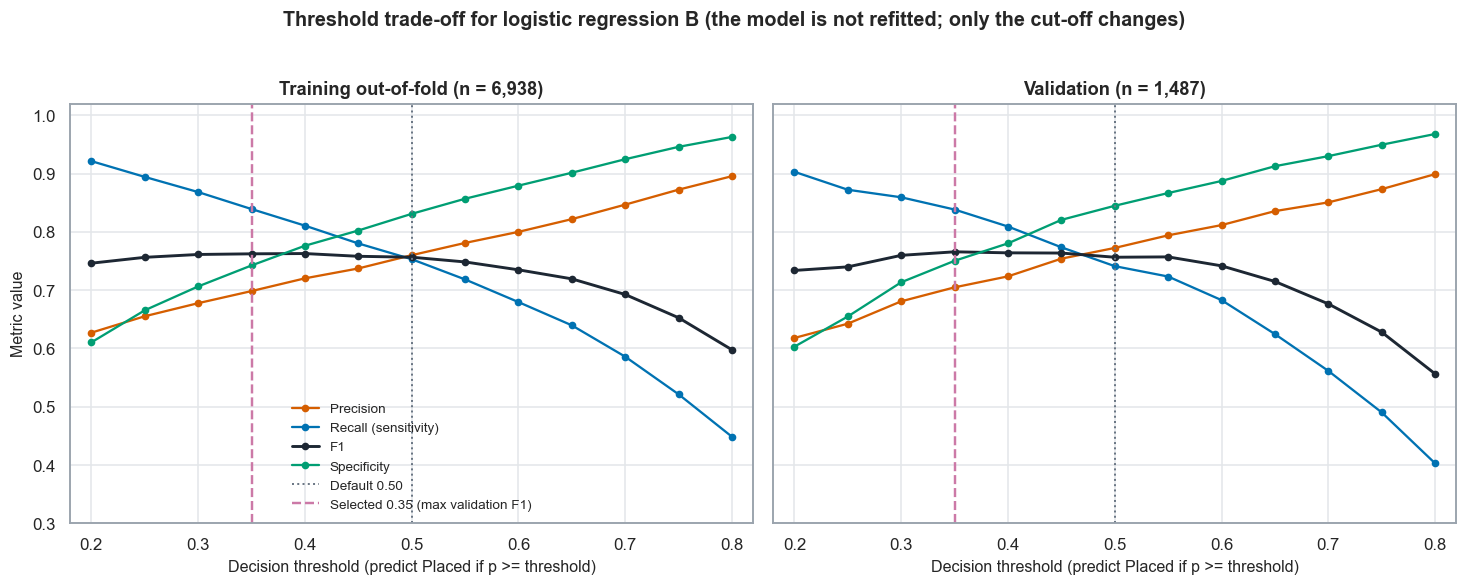

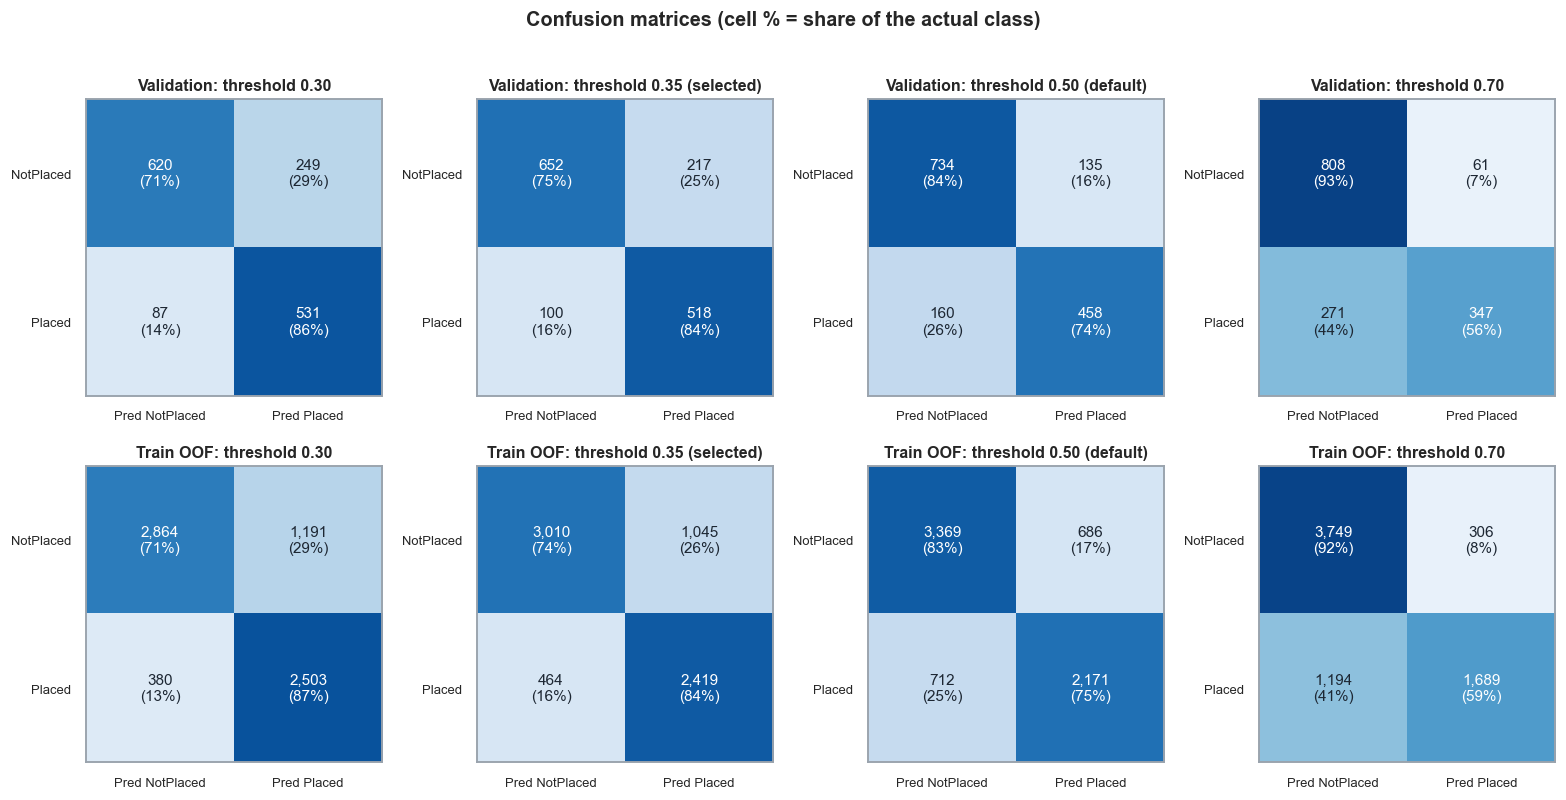

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), sharey=True)
for ax, (tb, ttl) in zip(axes, [(tab_oof, "Training out-of-fold (n = 6,938)"), (tab_val, "Validation (n = 1,487)")]):
    for col, c, lab in [("precision", "#D55E00", "Precision"), ("recall_sensitivity", "#0072B2", "Recall (sensitivity)"), ("f1", "#1d2733", "F1"), ("specificity", "#009E73", "Specificity")]:
        ax.plot(tb.threshold, tb[col], "o-", color=c, lw=1.9 if col == "f1" else 1.5, ms=4, label=lab)
    ax.axvline(0.5, color=NEUTRAL, ls=":", lw=1.3, label="Default 0.50")
    ax.axvline(T_SEL, color="#CC79A7", ls="--", lw=1.6, label=f"Selected {T_SEL:.2f} (max validation F1)")
    ax.set_title(ttl); ax.set_xlabel("Decision threshold (predict Placed if p >= threshold)"); ax.set_xlim(0.18, 0.82); ax.set_ylim(0.3, 1.02)
axes[0].set_ylabel("Metric value"); axes[0].legend(frameon=False, fontsize=8.8, loc="lower center")
fig.suptitle("Threshold trade-off for logistic regression B (the model is not refitted; only the cut-off changes)", y=1.02, fontsize=13, fontweight="semibold")
savefig(fig, "phase6_threshold_metrics")

reps = sorted({0.30, 0.50, T_SEL, 0.70}); fig, axes = plt.subplots(2, len(reps), figsize=(3.6 * len(reps), 7.2))
for r, (y_, p_, nm) in enumerate([(y_va, p_va, "Validation"), (y_tr, p_oof, "Train OOF")]):
    for j, t in enumerate(reps):
        tp, tn, fp, fn = confusion(y_, p_, t); cm = np.array([[tn, fp], [fn, tp]]); ax = axes[r, j]
        ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
        for (a, b), v in np.ndenumerate(cm): ax.text(b, a, f"{v:,}\n({v / cm[a].sum():.0%})", ha="center", va="center", fontsize=10, color="white" if v / cm[a].sum() > 0.55 else "#1d2733")
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred NotPlaced", "Pred Placed"], fontsize=8.5); ax.set_yticks([0, 1]); ax.set_yticklabels(["NotPlaced", "Placed"], fontsize=8.5)
        tag = " (selected)" if np.isclose(t, T_SEL) else (" (default)" if np.isclose(t, 0.5) else ""); ax.set_title(f"{nm}: threshold {t:.2f}{tag}", fontsize=10.5); ax.grid(False)
fig.suptitle("Confusion matrices (cell % = share of the actual class)", y=1.01, fontsize=13, fontweight="semibold")
savefig(fig, "phase6_confusion_matrices")

# PART B - Logistic regression explainability
## B1. Coefficients and odds ratios
The coefficients below are those of the **fitted Phase 4 pipeline** (L2-penalised, C = 1). Continuous features were standardised with the training mean/SD, so their odds ratio is **per one training standard deviation**; count and binary features are one-hot, so their odds ratio is **relative to the stated reference category**. Odds ratios of different kinds are therefore *not directly comparable in size*.

**Confidence intervals.** The penalised fit has no exact standard errors. The 95% intervals shown are **Wald intervals from an unpenalised logistic regression (maximum likelihood) on exactly the same transformed training design**; with n = 6,938 and 15 parameters the L2 penalty at C = 1 shifts coefficients very little (the maximum absolute difference is reported). They are conditional on the chosen representation and reference levels, ignore selection of that representation, and treat training rows as independent. Their purpose is interpretability, not hypothesis testing.

In [7]:
names = list(pre.get_feature_names_out()); coef = lrm.coef_[0].copy(); intercept = float(lrm.intercept_[0])
scaler = pre.named_transformers_["num"]; sd_of = dict(zip(CONT, scaler.scale_)); mean_of = dict(zip(CONT, scaler.mean_))     # scale_ is the ddof=0 SD actually used
Xt_tr = pre.transform(X_tr); assert list(Xt_tr.columns) == names

def base_of(nm):
    hits = [c for c in FEATURES if nm == c or nm.startswith(c + "_")]; return max(hits, key=len)
rows = []
for nm, b in zip(names, coef):
    base = base_of(nm)
    if base in CONT:
        rep, ref, unit, n_lvl, sd = "standardised continuous", "- (train mean)", "per 1 training SD", np.nan, sd_of[base]; orig = float(np.exp(b / sd))
    else:
        lvl = nm[len(base) + 1:]; rep = "one-hot count level" if base in COUNT else "binary"; ref = str(REFS[base]) if base in COUNT else "No"
        unit = f"{base} = {lvl} vs {ref}"; n_lvl = int((Xt_tr[nm] == 1).sum()); sd = np.nan; orig = np.nan
    rows.append({"feature": nm, "base_feature": base, "representation": rep, "reference_category": ref, "effect_unit": unit, "train_sd": sd, "n_train_with_level": n_lvl,
                 "coefficient_log_odds": b, "odds_ratio": float(np.exp(b)), "odds_ratio_per_original_unit": orig,
                 "direction": "associated with HIGHER predicted placement odds" if b > 0 else "associated with LOWER predicted placement odds"})
coefs = pd.DataFrame(rows)

# unpenalised MLE on the identical design -> Wald 95% intervals
mle = sm.Logit(y_tr, sm.add_constant(Xt_tr, has_constant="add")).fit(disp=0)
assert mle.mle_retvals["converged"]
mci = mle.conf_int(); mci.columns = ["lo", "hi"]
coefs["mle_coefficient"] = [float(mle.params[n]) for n in names]
coefs["ci95_lo_log_odds"] = [float(mci.loc[n, "lo"]) for n in names]; coefs["ci95_hi_log_odds"] = [float(mci.loc[n, "hi"]) for n in names]
coefs["odds_ratio_ci95_lo"] = np.exp(coefs.ci95_lo_log_odds); coefs["odds_ratio_ci95_hi"] = np.exp(coefs.ci95_hi_log_odds)
coefs["ci_includes_OR_1"] = (coefs.odds_ratio_ci95_lo <= 1) & (coefs.odds_ratio_ci95_hi >= 1)
coefs["small_level_flag"] = coefs.n_train_with_level < 50
coefs["abs_coefficient"] = coefs.coefficient_log_odds.abs()
coefs = coefs.sort_values("abs_coefficient", ascending=False).reset_index(drop=True); coefs["rank_by_abs_coefficient"] = np.arange(1, len(coefs) + 1)
maxdiff = float((coefs.coefficient_log_odds - coefs.mle_coefficient).abs().max())
coefs.drop(columns="abs_coefficient").to_csv(MET / "07_logistic_coefficients.csv", index=False)
print(f"Intercept (reference profile at the training mean, all one-hot levels at reference): {intercept:.3f} (log-odds)")
maxdiff_ex = float((coefs.coefficient_log_odds - coefs.mle_coefficient).abs()[coefs.feature != "Projects_0"].max())
print(f"Max |penalised - unpenalised| coefficient difference: {maxdiff:.4f} log-odds overall, but {maxdiff_ex:.4f} excluding Projects_0 (n = 19 training students, shrunk by the L2 penalty).")
print("-> for every level with a reasonable sample the unpenalised intervals are a close guide to the penalised fit; for Projects_0 the interval is wide and the penalised estimate is pulled toward 0.")
display(coefs[["rank_by_abs_coefficient", "feature", "effect_unit", "coefficient_log_odds", "odds_ratio", "odds_ratio_ci95_lo", "odds_ratio_ci95_hi", "odds_ratio_per_original_unit", "n_train_with_level", "small_level_flag"]].round(3).set_index("rank_by_abs_coefficient"))

Intercept (reference profile at the training mean, all one-hot levels at reference): -1.690 (log-odds)
Max |penalised - unpenalised| coefficient difference: 0.1621 log-odds overall, but 0.0055 excluding Projects_0 (n = 19 training students, shrunk by the L2 penalty).
-> for every level with a reasonable sample the unpenalised intervals are a close guide to the penalised fit; for Projects_0 the interval is wide and the penalised estimate is pulled toward 0.


,feature,effect_unit,coefficient_log_odds,odds_ratio,odds_ratio_ci95_lo,odds_ratio_ci95_hi,odds_ratio_per_original_unit,n_train_with_level,small_level_flag
rank_by_abs_coefficient,,,,,,,,,
1,PlacementTraining_Yes,PlacementTraining = Yes vs No,1.011,2.749,2.328,3.282,NaN,5075.0,False
2,ExtracurricularActivities_Yes,ExtracurricularActivities = Yes vs No,0.666,1.947,1.657,2.282,NaN,4045.0,False
3,Projects_0,Projects = 0 vs 3,0.504,1.655,0.627,6.041,NaN,19.0,True
4,AptitudeTestScore,per 1 training SD,0.500,1.649,1.505,1.805,1.063,NaN,False
5,Workshops/Certifications_2,Workshops/Certifications = 2 vs 0,0.426,1.531,1.299,1.801,NaN,2270.0,False
6,Projects_1,Projects = 1 vs 3,-0.414,0.661,0.549,0.789,NaN,2466.0,False
7,Projects_2,Projects = 2 vs 3,-0.320,0.726,0.613,0.856,NaN,1780.0,False
8,Workshops/Certifications_1,Workshops/Certifications = 1 vs 0,-0.313,0.731,0.614,0.861,NaN,1868.0,False
9,SSC_Marks,per 1 training SD,0.286,1.332,1.230,1.441,1.028,NaN,False


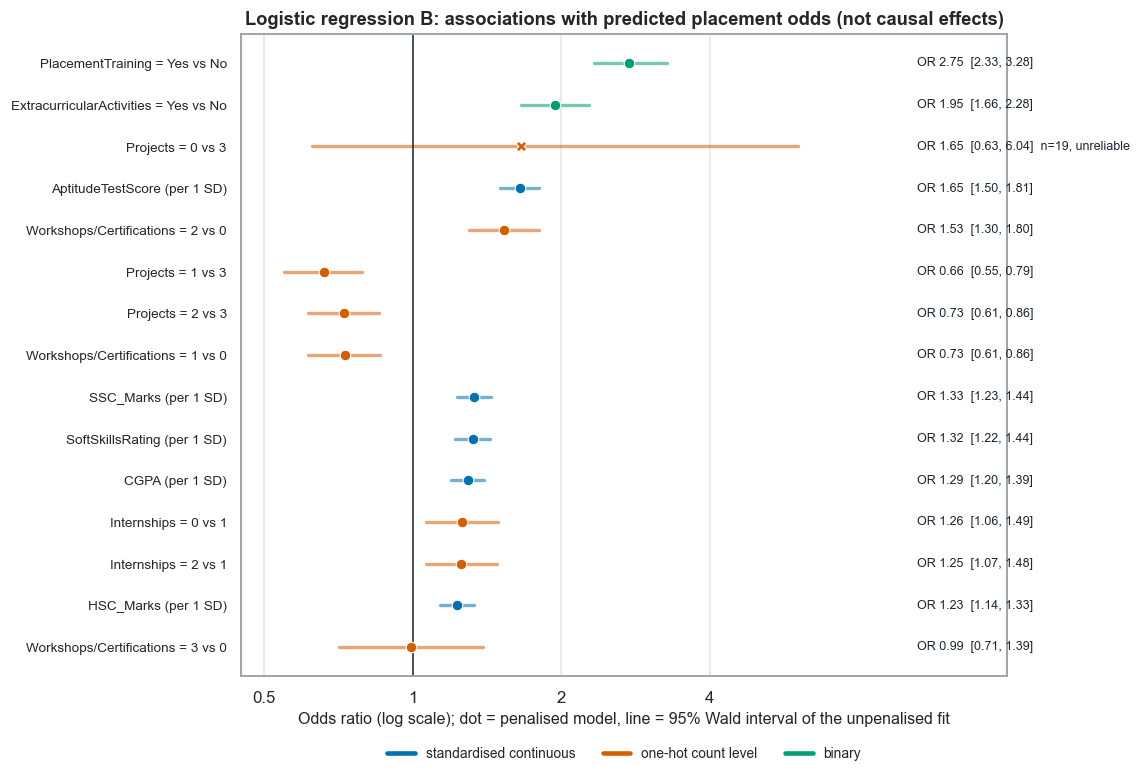

In [8]:
fig, ax = plt.subplots(figsize=(10.4, 7.2)); d_ = coefs.iloc[::-1].reset_index(drop=True); ypos = np.arange(len(d_))
colmap = {"standardised continuous": "#0072B2", "one-hot count level": "#D55E00", "binary": "#009E73"}
ax.set_xscale("log"); ax.set_xlim(0.45, 16); XT = 10.5            # value labels sit in a fixed right-hand column
for i, r in d_.iterrows():
    c = colmap[r.representation]
    ax.plot([r.odds_ratio_ci95_lo, r.odds_ratio_ci95_hi], [i, i], color=c, lw=2.2, alpha=0.55, solid_capstyle="round")
    ax.scatter(r.odds_ratio, i, color=c, s=48, zorder=3, edgecolor="white", linewidth=0.7, marker="o" if not r.small_level_flag else "X")
    ax.text(XT, i, f"OR {r.odds_ratio:.2f}  [{r.odds_ratio_ci95_lo:.2f}, {r.odds_ratio_ci95_hi:.2f}]" + ("  n=%d, unreliable" % r.n_train_with_level if r.small_level_flag else ""), va="center", fontsize=8.2, color="#1d2733")
ylabels = [(f"{r.base_feature} (per 1 SD)" if r.representation == "standardised continuous" else r.effect_unit) for _, r in d_.iterrows()]
ax.axvline(1, color="#1d2733", lw=1); ax.set_yticks(ypos); ax.set_yticklabels(ylabels, fontsize=8.8)
ax.set_xticks([0.5, 1, 2, 4]); ax.set_xticklabels(["0.5", "1", "2", "4"]); ax.minorticks_off()
ax.set_xlabel("Odds ratio (log scale); dot = penalised model, line = 95% Wald interval of the unpenalised fit")
ax.set_title("Logistic regression B: associations with predicted placement odds (not causal effects)")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0], [0], color=c, lw=3, label=k) for k, c in colmap.items()], frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3, fontsize=9); ax.grid(axis="y", visible=False)
savefig(fig, "phase6_logistic_coefficients")

## B2. Permutation importance (validation set)
Each of the **10 raw input columns** is shuffled (the three count variables are permuted as whole columns, not level by level) in the *full pipeline*, 20 repeats, `random_state = 42`, and the drop in performance is recorded. Scores: **ROC-AUC** (primary; importance = AUC lost) and **log loss** (secondary; importance = log loss *added*, so positive = worse after shuffling). Evaluated on validation, never train. Permutation importance measures how much the **fitted model relies on a column for prediction**; it does not establish causation, and with correlated predictors (e.g. aptitude / HSC marks, r about 0.56) credit is shared, so single values are not exclusive contributions.

In [9]:
t0 = time.time()
pi = permutation_importance(LR, X_va, y_va, scoring={"roc_auc": "roc_auc", "neg_log_loss": "neg_log_loss"}, n_repeats=20, random_state=SEED, n_jobs=1)
perm = pd.DataFrame({"feature": FEATURES,
                     "auc_importance_mean": pi["roc_auc"]["importances_mean"], "auc_importance_sd": pi["roc_auc"]["importances_std"],
                     "logloss_importance_mean": pi["neg_log_loss"]["importances_mean"], "logloss_importance_sd": pi["neg_log_loss"]["importances_std"]})
perm["rank_by_auc"] = perm.auc_importance_mean.rank(ascending=False, method="min").astype(int)
perm["rank_by_logloss"] = perm.logloss_importance_mean.rank(ascending=False, method="min").astype(int)
perm["n_repeats"] = 20; perm["baseline_val_auc"] = roc_auc_score(y_va, p_va); perm["baseline_val_log_loss"] = log_loss(y_va, p_va)
perm = perm.sort_values("auc_importance_mean", ascending=False).reset_index(drop=True); perm.to_csv(MET / "07_permutation_importance.csv", index=False)
print(f"done in {time.time() - t0:.0f}s | baseline validation AUC {perm.baseline_val_auc[0]:.4f}, log loss {perm.baseline_val_log_loss[0]:.4f}")
display(perm.round(4).set_index("feature"))

done in 5s | baseline validation AUC 0.8717, log loss 0.4408


,auc_importance_mean,auc_importance_sd,logloss_importance_mean,logloss_importance_sd,rank_by_auc,rank_by_logloss,n_repeats,baseline_val_auc,baseline_val_log_loss
feature,,,,,,,,,
AptitudeTestScore,0.0208,0.0036,0.0333,0.0047,1,1,20,0.8717,0.4408
PlacementTraining,0.0177,0.0043,0.0267,0.0062,2,2,20,0.8717,0.4408
ExtracurricularActivities,0.0125,0.0022,0.0189,0.0029,3,3,20,0.8717,0.4408
Workshops/Certifications,0.0081,0.0015,0.0136,0.0023,4,4,20,0.8717,0.4408
SoftSkillsRating,0.0060,0.0015,0.0098,0.0021,5,5,20,0.8717,0.4408
SSC_Marks,0.0050,0.0019,0.0087,0.0027,6,6,20,0.8717,0.4408
Projects,0.0039,0.0011,0.0069,0.0016,7,7,20,0.8717,0.4408
HSC_Marks,0.0038,0.0016,0.0064,0.0022,8,9,20,0.8717,0.4408
CGPA,0.0036,0.0013,0.0064,0.0020,9,8,20,0.8717,0.4408


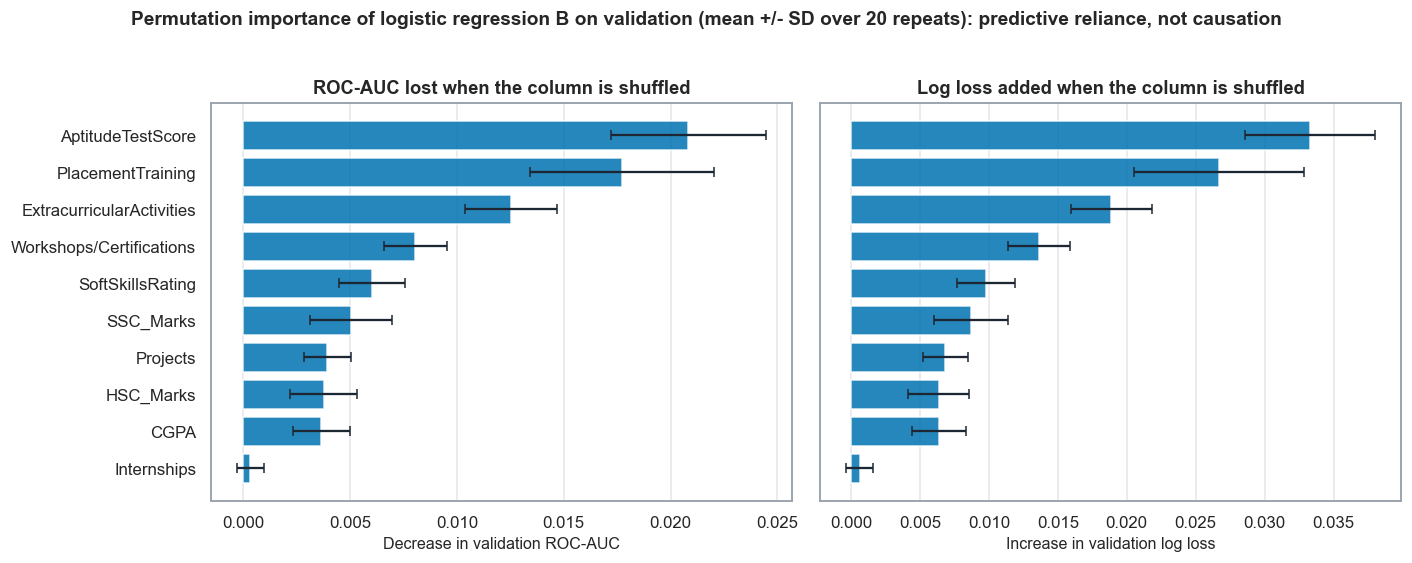

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.0), sharey=True); d_ = perm.iloc[::-1]
for ax, (mc, sc, ttl, xl) in zip(axes, [("auc_importance_mean", "auc_importance_sd", "ROC-AUC lost when the column is shuffled", "Decrease in validation ROC-AUC"),
                                        ("logloss_importance_mean", "logloss_importance_sd", "Log loss added when the column is shuffled", "Increase in validation log loss")]):
    ax.barh(d_.feature, d_[mc], xerr=d_[sc], color=LR_C, alpha=0.85, ecolor="#1d2733", capsize=3); ax.set_xlabel(xl); ax.set_title(ttl); ax.grid(axis="y", visible=False)
fig.suptitle("Permutation importance of logistic regression B on validation (mean +/- SD over 20 repeats): predictive reliance, not causation", y=1.02, fontsize=12.5, fontweight="semibold")
savefig(fig, "phase6_permutation_importance")

## B3. Global comparison: coefficients vs permutation importance
The two methods answer different questions, and the coefficient table mixes units (per SD, versus a level contrast). To put coefficients on a common footing per raw feature, each feature's **contribution to the linear predictor** is computed for every validation student, `sum of (coefficient x transformed value)` over the feature's columns, and its **standard deviation across students** is reported. For a standardised feature this is |coefficient| (times its z-score SD, about 1); for a one-hot feature it accounts for how common each level is, so a rare level (e.g. Projects = 0, 19 training students) cannot dominate. This is a descriptive summary of the fitted model, not a causal ranking.

In [11]:
Xt_va = pre.transform(X_va); assert np.allclose(Xt_va.to_numpy() @ coef + intercept, LR.decision_function(X_va), atol=1e-9)
contrib_cols = pd.DataFrame(Xt_va.to_numpy() * coef, columns=names, index=X_va.index)
contrib_va = pd.DataFrame({f: contrib_cols[[n for n in names if base_of(n) == f]].sum(axis=1) for f in FEATURES})
assert np.allclose(contrib_va.sum(axis=1) + intercept, LR.decision_function(X_va), atol=1e-9)
gc = perm.set_index("feature")[["auc_importance_mean", "auc_importance_sd", "rank_by_auc", "logloss_importance_mean", "rank_by_logloss"]].copy()
gc["contribution_sd_validation"] = contrib_va.std(ddof=0)[gc.index]; gc["rank_by_contribution_sd"] = gc.contribution_sd_validation.rank(ascending=False, method="min").astype(int)
def coef_summary(f):
    r = coefs[coefs.base_feature == f]
    if f in CONT: return f"{r.coefficient_log_odds.iloc[0]:+.2f} log-odds per 1 SD (OR {r.odds_ratio.iloc[0]:.2f})"
    return "; ".join(f"{x.effect_unit.split(' = ')[1]}: OR {x.odds_ratio:.2f}" for x in r.sort_values("feature").itertuples())
gc["coefficient_summary"] = [coef_summary(f) for f in gc.index]
gc = gc.sort_values("rank_by_auc"); gc.reset_index().to_csv(MET / "07_global_explainability_comparison.csv", index=False)
rho = stats.spearmanr(gc.rank_by_contribution_sd, gc.rank_by_auc)
print(f"Spearman correlation between the two rankings (10 features; only a rough guide): rho = {rho.statistic:.2f}")
display(gc[["rank_by_auc", "auc_importance_mean", "rank_by_logloss", "rank_by_contribution_sd", "contribution_sd_validation", "coefficient_summary"]].round(4))

Spearman correlation between the two rankings (10 features; only a rough guide): rho = 0.92


,rank_by_auc,auc_importance_mean,rank_by_logloss,rank_by_contribution_sd,contribution_sd_validation,coefficient_summary
feature,,,,,,
AptitudeTestScore,1,0.0208,1,1,0.4987,+0.50 log-odds per 1 SD (OR 1.65)
PlacementTraining,2,0.0177,2,2,0.4528,Yes vs No: OR 2.75
ExtracurricularActivities,3,0.0125,3,3,0.3282,Yes vs No: OR 1.95
Workshops/Certifications,4,0.0081,4,5,0.2868,1 vs 0: OR 0.73; 2 vs 0: OR 1.53; 3 vs 0: OR 0.99
SoftSkillsRating,5,0.0060,5,6,0.2785,+0.28 log-odds per 1 SD (OR 1.32)
SSC_Marks,6,0.0050,6,4,0.2934,+0.29 log-odds per 1 SD (OR 1.33)
Projects,7,0.0039,7,9,0.1882,0 vs 3: OR 1.65; 1 vs 3: OR 0.66; 2 vs 3: OR 0.73
HSC_Marks,8,0.0038,9,8,0.2110,+0.21 log-odds per 1 SD (OR 1.23)
CGPA,9,0.0036,8,7,0.2590,+0.26 log-odds per 1 SD (OR 1.29)


# PART C - Individual validation-student explanations
For logistic regression the log-odds are exactly additive: `log-odds = intercept + sum_j coefficient_j x transformed_value_j`. A feature's **contribution** is the sum of its terms; it is measured **relative to a baseline profile**: the *training mean* for standardised features and the *reference level* for one-hot features. A positive contribution means the value **raises the model's predicted log-odds** of placement relative to that baseline; it does not mean the value causes placement.

**Six cases, chosen by fixed deterministic rules** (ties -> lowest row index; all six are distinct validation students):
1. *Very high probability* - correctly classified Placed student closest to the 95th percentile of validation probabilities.
2. *Very low probability* - correctly classified NotPlaced student closest to the 5th percentile.
3. *Decision boundary* - closest to p = 0.50.
4. *False positive* - the **most confident** false positive at 0.50 (highest p among NotPlaced). Deliberately the extreme error, not a typical one.
5. *False negative* - the **most confident** false negative at 0.50 (lowest p among Placed).
6. *Middle / uncertain* - closest to the median validation probability.

In [12]:
used = set(); pick = {}
def choose(label, mask, target=None, extreme=None):
    cand = np.where(mask)[0]; cand = [i for i in cand if i not in used]
    if extreme == "max": i = max(cand, key=lambda j: (p_va[j], -j))
    elif extreme == "min": i = min(cand, key=lambda j: (p_va[j], j))
    else: i = min(cand, key=lambda j: (abs(p_va[j] - target), j))
    used.add(i); pick[label] = int(i)
q95, q05, med = np.quantile(p_va, 0.95), np.quantile(p_va, 0.05), np.median(p_va)
choose("1 very high probability", (y_va == 1) & (p_va >= 0.5), target=q95)
choose("2 very low probability", (y_va == 0) & (p_va < 0.5), target=q05)
choose("3 decision boundary", np.ones(len(y_va), bool), target=0.5)
choose("4 false positive (most confident)", (y_va == 0) & (p_va >= 0.5), extreme="max")
choose("5 false negative (most confident)", (y_va == 1) & (p_va < 0.5), extreme="min")
choose("6 middle / uncertain", np.ones(len(y_va), bool), target=med)
assert len(set(pick.values())) == 6
rules = {"1 very high probability": f"correct Placed closest to 95th percentile of p ({q95:.3f})", "2 very low probability": f"correct NotPlaced closest to 5th percentile of p ({q05:.3f})",
         "3 decision boundary": "closest to p = 0.50", "4 false positive (most confident)": "highest p among NotPlaced (p >= 0.50)",
         "5 false negative (most confident)": "lowest p among Placed (p < 0.50)", "6 middle / uncertain": f"closest to median validation p ({med:.3f})"}
long_rows, sum_rows = [], []
for lab, i in pick.items():
    p_i, y_i = p_va[i], y_va[i]; cv = contrib_va.iloc[i]; assert abs(intercept + cv.sum() - LR.decision_function(X_va.iloc[[i]])[0]) < 1e-9
    for f in FEATURES:
        long_rows.append({"case": lab, "val_row_id": i, "feature": f, "input_value": X_va.iloc[i][f], "contribution_log_odds": float(cv[f]),
                          "effect_on_predicted_log_odds": "raises" if cv[f] > 0.05 else ("lowers" if cv[f] < -0.05 else "negligible (|c| <= 0.05)")})
    long_rows.append({"case": lab, "val_row_id": i, "feature": "(intercept: reference profile)", "input_value": np.nan, "contribution_log_odds": intercept, "effect_on_predicted_log_odds": "baseline"})
    pos = cv[cv > 0.05].sort_values(ascending=False).head(3); neg = cv[cv < -0.05].sort_values().head(3)
    fmt = lambda s: "; ".join(f"{f} = {X_va.iloc[i][f]:g} ({c:+.2f})" if not isinstance(X_va.iloc[i][f], str) else f"{f} = {X_va.iloc[i][f]} ({c:+.2f})" for f, c in s.items()) or "none"
    sum_rows.append({"case": lab, "selection_rule": rules[lab], "val_row_id": i, "actual": "Placed" if y_i else "NotPlaced", "predicted_probability": p_i, "total_log_odds": intercept + cv.sum(),
                     "class_at_0.50": "Placed" if p_i >= 0.5 else "NotPlaced", f"class_at_selected_{T_SEL:.2f}": "Placed" if p_i >= T_SEL else "NotPlaced",
                     "major_positive_contributions": fmt(pos), "major_negative_contributions": fmt(neg),
                     **{f"input_{f}": X_va.iloc[i][f] for f in FEATURES}})
expl_long, expl_sum = pd.DataFrame(long_rows), pd.DataFrame(sum_rows)
expl_long.to_csv(MET / "07_individual_explanations.csv", index=False); expl_sum.to_csv(MET / "07_individual_explanation_summary.csv", index=False)
print("Saved long-format contributions (07_individual_explanations.csv) and one-row-per-case summary.")
pd.set_option("display.max_colwidth", 140)
display(expl_sum[["case", "actual", "predicted_probability", "class_at_0.50", f"class_at_selected_{T_SEL:.2f}", "major_positive_contributions", "major_negative_contributions"]].round(3).set_index("case"))
display(expl_sum[["case"] + [f"input_{f}" for f in FEATURES]].set_index("case"))

Saved long-format contributions (07_individual_explanations.csv) and one-row-per-case summary.


,actual,predicted_probability,class_at_0.50,class_at_selected_0.35,major_positive_contributions,major_negative_contributions
case,,,,,,
1 very high probability,Placed,0.908,Placed,Placed,PlacementTraining = Yes (+1.01); ExtracurricularActivities = Yes (+0.67); AptitudeTestScore = 87 (+0.47),none
2 very low probability,NotPlaced,0.022,NotPlaced,NotPlaced,CGPA = 8 (+0.12),AptitudeTestScore = 69 (-0.63); SoftSkillsRating = 3.6 (-0.49); Projects = 1 (-0.41)
3 decision boundary,Placed,0.501,Placed,Placed,PlacementTraining = Yes (+1.01); ExtracurricularActivities = Yes (+0.67); HSC_Marks = 88 (+0.32),Projects = 1 (-0.41); AptitudeTestScore = 76 (-0.20); CGPA = 7.5 (-0.08)
4 false positive (most confident),NotPlaced,0.926,Placed,Placed,PlacementTraining = Yes (+1.01); ExtracurricularActivities = Yes (+0.67); AptitudeTestScore = 90 (+0.65),none
5 false negative (most confident),Placed,0.020,NotPlaced,NotPlaced,none,SoftSkillsRating = 3.6 (-0.49); CGPA = 6.6 (-0.44); Projects = 1 (-0.41)
6 middle / uncertain,NotPlaced,0.338,NotPlaced,NotPlaced,PlacementTraining = Yes (+1.01); SSC_Marks = 83 (+0.38); SoftSkillsRating = 4.8 (+0.32),Projects = 2 (-0.32); Workshops/Certifications = 1 (-0.31); CGPA = 7.3 (-0.16)


,input_CGPA,input_Internships,input_Projects,input_Workshops/Certifications,input_AptitudeTestScore,input_SoftSkillsRating,input_ExtracurricularActivities,input_PlacementTraining,input_SSC_Marks,input_HSC_Marks
case,,,,,,,,,,
1 very high probability,8.7,2,3,2,87,4.7,Yes,Yes,80,84
2 very low probability,8.0,1,1,0,69,3.6,No,No,55,62
3 decision boundary,7.5,1,1,0,76,4.5,Yes,Yes,79,88
4 false positive (most confident),8.6,2,3,2,90,4.8,Yes,Yes,80,85
5 false negative (most confident),6.6,1,1,1,75,3.6,No,No,61,72
6 middle / uncertain,7.3,0,2,1,78,4.8,No,Yes,83,72


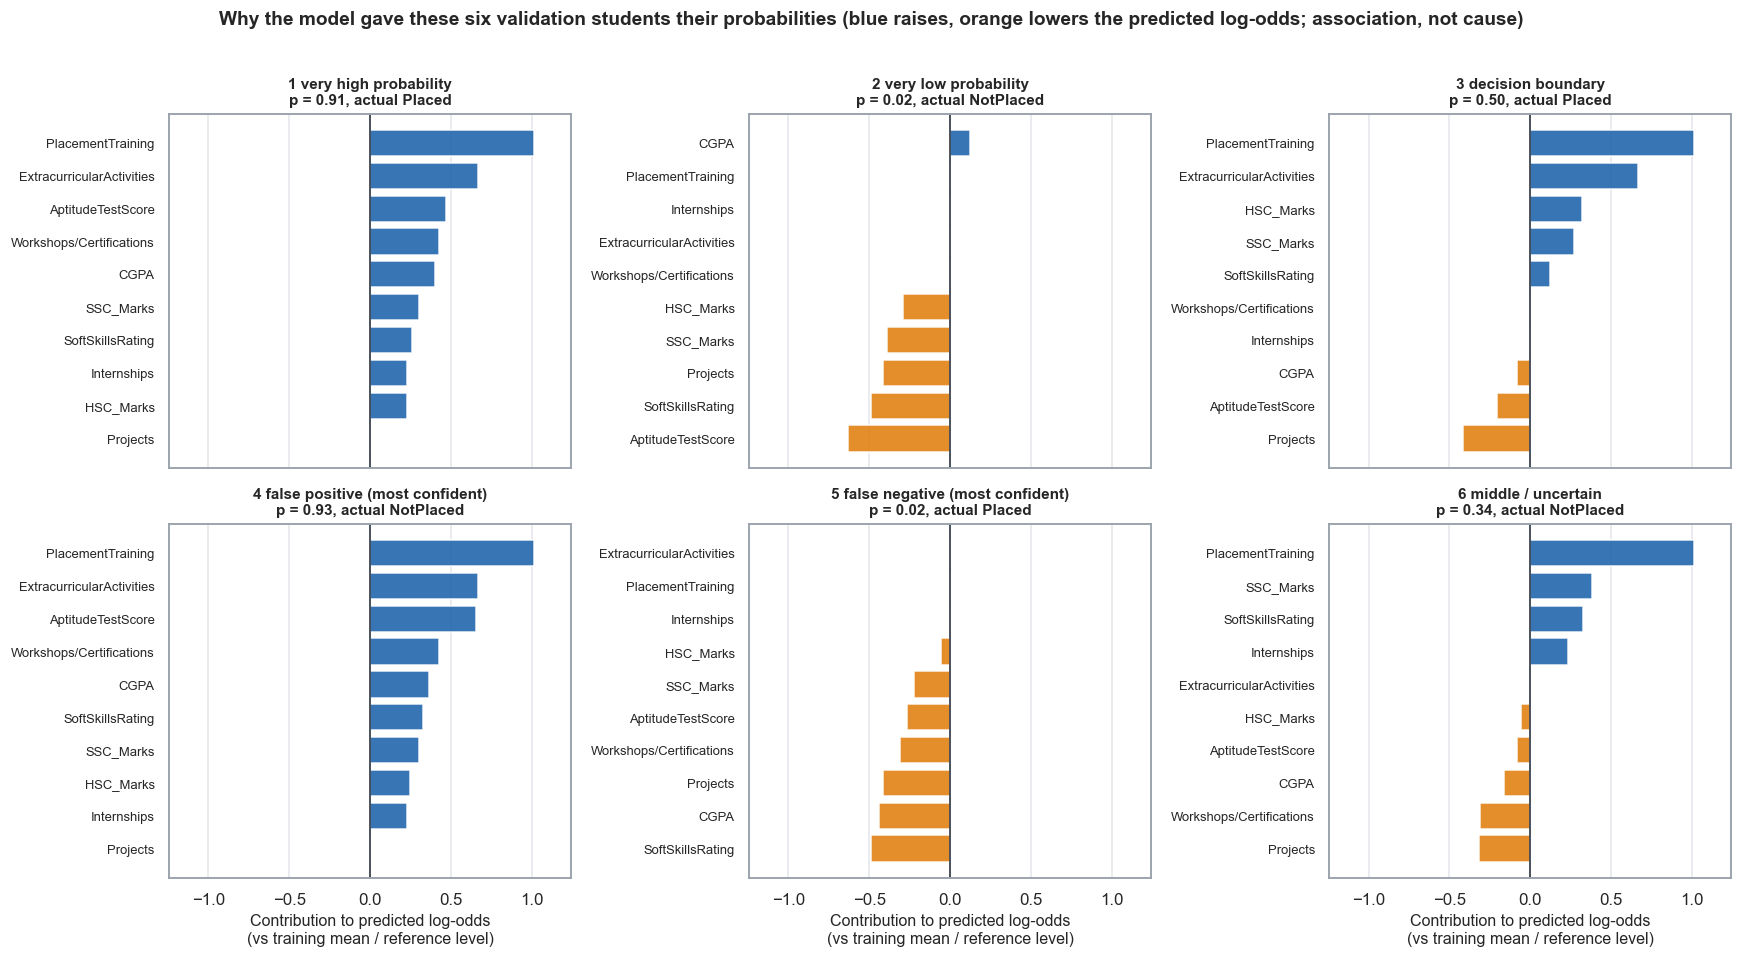

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.6), sharex=True)
lim = np.abs(contrib_va.to_numpy()).max() * 1.05
for ax, (lab, i) in zip(axes.ravel(), pick.items()):
    cv = contrib_va.iloc[i].sort_values(); ax.barh(cv.index, cv.values, color=np.where(cv.values >= 0, PLACED_C, NOT_C), alpha=0.9)
    ax.axvline(0, color="#1d2733", lw=1); ax.set_xlim(-lim, lim); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5)
    ax.set_title(f"{lab}\np = {p_va[i]:.2f}, actual {'Placed' if y_va[i] else 'NotPlaced'}", fontsize=10)
for ax in axes[1]: ax.set_xlabel("Contribution to predicted log-odds\n(vs training mean / reference level)")
fig.suptitle("Why the model gave these six validation students their probabilities (blue raises, orange lowers the predicted log-odds; association, not cause)", y=1.01, fontsize=12.5, fontweight="semibold")
savefig(fig, "phase6_individual_explanations")

# PART D - Feature-group ablation (logistic regression)
Five logistic regressions, each with the **same preprocessing philosophy and regularisation as `LR_B`** (L2, C = 1; continuous scores standardised; counts one-hot with the fixed Phase 4 reference levels 1 / 3 / 0; binary variables one-hot with reference `No`; transformers are simply omitted for groups that lack that kind of feature). IDs are `ABL_A`...`ABL_E` to avoid confusion with the Phase 4 *Representations* A and B (`LR_B` is Representation B).

| ID | Group | Features |
|---|---|---|
| ABL_A | Academic only | CGPA, SSC_Marks, HSC_Marks |
| ABL_B | Academic + Aptitude | + AptitudeTestScore |
| ABL_C | Academic + Technical | + Internships, Projects, Workshops/Certifications |
| ABL_D | Employability only | SoftSkillsRating, ExtracurricularActivities, PlacementTraining |
| ABL_E | Full model | all 10 predictors (must reproduce `LR_B`) |

**Evaluation.** 5-fold stratified CV on TRAIN (the same folds as Phase 5), then fit on all of TRAIN and evaluate once on VALIDATION. F1 uses the default 0.50 threshold (no per-model threshold search). Validation 95% intervals and paired differences use 1,000 paired bootstrap resamples. **Caveats:** the groups overlap conceptually and are correlated, and a group's gain depends on what is already in the model (employability's gain is measured only on top of everything else, C to E; ABL_D gives its stand-alone value). Differences describe predictive improvement, not effects.

In [14]:
GROUPS = {"ABL_A": ("Academic only", ["CGPA", "SSC_Marks", "HSC_Marks"]),
          "ABL_B": ("Academic + Aptitude", ["CGPA", "SSC_Marks", "HSC_Marks", "AptitudeTestScore"]),
          "ABL_C": ("Academic + Technical", ["CGPA", "SSC_Marks", "HSC_Marks", "AptitudeTestScore", "Internships", "Projects", "Workshops/Certifications"]),
          "ABL_D": ("Employability only", ["SoftSkillsRating", "ExtracurricularActivities", "PlacementTraining"]),
          "ABL_E": ("Full model", FEATURES)}
def make_lr(cols):
    cont, cnt, bn = [c for c in CONT if c in cols], [c for c in COUNT if c in cols], [c for c in BIN if c in cols]
    parts = []
    if cont: parts.append(("num", StandardScaler(), cont))
    if cnt: parts.append(("cnt", OneHotEncoder(drop=[REFS[c] for c in cnt], sparse_output=False, handle_unknown="error"), cnt))
    if bn: parts.append(("bin", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="error"), bn))
    assert sorted(cont + cnt + bn) == sorted(cols)
    return Pipeline([("prep", ColumnTransformer(parts, verbose_feature_names_out=False).set_output(transform="pandas")),
                     ("model", LogisticRegression(l1_ratio=0, solver="lbfgs", max_iter=5000, random_state=SEED))])
for g, (_, cols) in GROUPS.items(): print(g, len(cols), cols)

# the full model must reproduce Phase 4 / Phase 5 exactly -> proves "same preprocessing"
full = make_lr(FEATURES).fit(X_tr, y_tr)
assert np.allclose(full.predict_proba(X_va)[:, 1], p_va, atol=1e-9), "ABL_E does not reproduce the Phase 4 LR_B validation probabilities"
assert np.allclose(full.named_steps["model"].coef_, lrm.coef_, atol=1e-8)
print("ABL_E reproduces the Phase 4 LR_B validation probabilities and coefficients.")

ABL_A 3 ['CGPA', 'SSC_Marks', 'HSC_Marks']
ABL_B 4 ['CGPA', 'SSC_Marks', 'HSC_Marks', 'AptitudeTestScore']
ABL_C 7 ['CGPA', 'SSC_Marks', 'HSC_Marks', 'AptitudeTestScore', 'Internships', 'Projects', 'Workshops/Certifications']
ABL_D 3 ['SoftSkillsRating', 'ExtracurricularActivities', 'PlacementTraining']
ABL_E 10 ['CGPA', 'Internships', 'Projects', 'Workshops/Certifications', 'AptitudeTestScore', 'SoftSkillsRating', 'ExtracurricularActivities', 'PlacementTraining', 'SSC_Marks', 'HSC_Marks']
ABL_E reproduces the Phase 4 LR_B validation probabilities and coefficients.


In [15]:
t0 = time.time(); fold_rows, oof_abl, val_p = [], {g: np.full(len(y_tr), np.nan) for g in GROUPS}, {}
for g, (lab, cols) in GROUPS.items():
    for k, (tr, te) in enumerate(outer, 1):
        pipe = make_lr(cols).fit(X_tr.iloc[tr][cols], y_tr[tr]); p = pipe.predict_proba(X_tr.iloc[te][cols])[:, 1]; oof_abl[g][te] = p
        fold_rows.append({"group_id": g, "group": lab, "fold": k, **metrics_all(p, y_tr[te])})
    val_p[g] = make_lr(cols).fit(X_tr[cols], y_tr).predict_proba(X_va[cols])[:, 1]
assert all(not np.isnan(oof_abl[g]).any() for g in GROUPS)
assert np.allclose(oof_abl["ABL_E"], p_oof, atol=1e-8), "ABL_E OOF does not reproduce Phase 5 logistic OOF"
print(f"ablation CV + validation fits done in {time.time() - t0:.0f}s; ABL_E OOF reproduces the Phase 5 logistic OOF probabilities.")
fr_ab = pd.DataFrame(fold_rows); fr_ab.to_csv(MET / "07_feature_ablation_fold_results.csv", index=False)

# validation bootstrap (paired: same resamples for every group)
MET_NAMES = ["roc_auc", "log_loss", "brier", "f1"]
def boot_metrics(p):
    out = {k: np.empty(B_BOOT) for k in MET_NAMES}; ll = -(y_va * np.log(np.clip(p, 1e-15, 1 - 1e-15)) + (1 - y_va) * np.log(1 - np.clip(p, 1e-15, 1 - 1e-15))); br = (p - y_va) ** 2
    out["log_loss"], out["brier"] = ll[IDXV].mean(1), br[IDXV].mean(1); out["f1"] = f1_boot(y_va, p >= 0.5, IDXV)
    out["roc_auc"] = np.array([roc_auc_score(y_va[ix], p[ix]) for ix in IDXV]); return out
BOOT = {g: boot_metrics(val_p[g]) for g in GROUPS}
rows = []
for g, (lab, cols) in GROUPS.items():
    sub = fr_ab[fr_ab.group_id == g]; vm = metrics_all(val_p[g], y_va)
    r = {"group_id": g, "group": lab, "n_features": len(cols), "features": ", ".join(cols)}
    for m in MET_NAMES:
        r[f"cv_{m}_mean"], r[f"cv_{m}_sd"] = sub[m].mean(), sub[m].std(); r[f"val_{m}"] = vm[m]
        r[f"val_{m}_ci_lo"], r[f"val_{m}_ci_hi"] = np.percentile(BOOT[g][m], [2.5, 97.5])
    r["val_accuracy"] = vm["accuracy"]; rows.append(r)
abl = pd.DataFrame(rows); abl.to_csv(MET / "07_feature_ablation.csv", index=False)
ref = metrics_all(np.full(len(y_va), BASE_RATE_TR), y_va)
print(f"Reference (always predict the train placement rate): validation AUC {ref['roc_auc']:.3f}, log loss {ref['log_loss']:.3f}, Brier {ref['brier']:.3f}")
cols_show = ["group", "n_features"] + [f"cv_{m}_mean" for m in MET_NAMES[:3]] + [f"cv_{m}_sd" for m in MET_NAMES[:3]] + ["cv_f1_mean"] + [f"val_{m}" for m in MET_NAMES]
display(abl.set_index("group_id")[cols_show].round(4))

ablation CV + validation fits done in 1s; ABL_E OOF reproduces the Phase 5 logistic OOF probabilities.


Reference (always predict the train placement rate): validation AUC 0.500, log loss 0.679, Brier 0.243


,group,n_features,cv_roc_auc_mean,cv_log_loss_mean,cv_brier_mean,cv_roc_auc_sd,cv_log_loss_sd,cv_brier_sd,cv_f1_mean,val_roc_auc,val_log_loss,val_brier,val_f1
group_id,,,,,,,,,,,,,
ABL_A,Academic only,3,0.8403,0.4876,0.1587,0.0128,0.0171,0.0066,0.7255,0.8227,0.5103,0.1659,0.7111
ABL_B,Academic + Aptitude,4,0.8590,0.4624,0.1500,0.0125,0.0179,0.0071,0.7352,0.8441,0.4818,0.1567,0.7337
ABL_C,Academic + Technical,7,0.8656,0.4513,0.1459,0.0109,0.0164,0.0064,0.7448,0.8558,0.4646,0.1502,0.7452
ABL_D,Employability only,3,0.8343,0.4955,0.1632,0.0036,0.0039,0.0017,0.7185,0.8280,0.5065,0.1660,0.7254
ABL_E,Full model,10,0.8790,0.4309,0.1392,0.0095,0.0157,0.0059,0.7564,0.8717,0.4408,0.1409,0.7564


In [16]:
# Increments: validation paired-bootstrap differences and paired CV-fold differences
PAIRS = [("ABL_B", "ABL_A", "adding aptitude to academic"), ("ABL_C", "ABL_B", "adding technical features (counts) to academic + aptitude"),
         ("ABL_E", "ABL_C", "adding employability to academic + technical"), ("ABL_E", "ABL_A", "full vs academic only"), ("ABL_E", "ABL_D", "full vs employability only"),
         ("ABL_C", "ABL_A", "academic + aptitude + technical vs academic only")]
inc = []
for big, small, desc in PAIRS:
    row = {"comparison": f"{big} minus {small}", "description": desc}
    for m in ["roc_auc", "log_loss", "brier"]:
        dv = BOOT[big][m] - BOOT[small][m]; fv = fr_ab[fr_ab.group_id == big].sort_values("fold")[m].to_numpy() - fr_ab[fr_ab.group_id == small].sort_values("fold")[m].to_numpy()
        row[f"val_d_{m}"] = float(abl.set_index("group_id").loc[big, f"val_{m}"] - abl.set_index("group_id").loc[small, f"val_{m}"])
        row[f"val_d_{m}_ci_lo"], row[f"val_d_{m}_ci_hi"] = np.percentile(dv, [2.5, 97.5]); row[f"cv_d_{m}_mean"], row[f"cv_d_{m}_sd"] = fv.mean(), fv.std(ddof=1)
        row[f"cv_folds_improved_{m}"] = int((fv > 0).sum() if m == "roc_auc" else (fv < 0).sum())
    inc.append(row)
inc = pd.DataFrame(inc); inc.to_csv(MET / "07_feature_ablation_increments.csv", index=False)
display(inc.set_index("comparison")[["val_d_roc_auc", "val_d_roc_auc_ci_lo", "val_d_roc_auc_ci_hi", "cv_d_roc_auc_mean", "cv_folds_improved_roc_auc", "val_d_log_loss", "val_d_log_loss_ci_lo", "val_d_log_loss_ci_hi", "cv_d_log_loss_mean", "cv_folds_improved_log_loss", "val_d_brier"]].round(4))
print("(AUC: positive = bigger model better; log loss / Brier: negative = bigger model better. Folds improved = of 5.)")

,val_d_roc_auc,val_d_roc_auc_ci_lo,val_d_roc_auc_ci_hi,cv_d_roc_auc_mean,cv_folds_improved_roc_auc,val_d_log_loss,val_d_log_loss_ci_lo,val_d_log_loss_ci_hi,cv_d_log_loss_mean,cv_folds_improved_log_loss,val_d_brier
comparison,,,,,,,,,,,
ABL_B minus ABL_A,0.0214,0.0129,0.0296,0.0187,5,-0.0285,-0.0399,-0.0176,-0.0252,5,-0.0092
ABL_C minus ABL_B,0.0117,0.0063,0.0176,0.0066,5,-0.0172,-0.0253,-0.0094,-0.0111,5,-0.0066
ABL_E minus ABL_C,0.0159,0.0084,0.0231,0.0134,5,-0.0237,-0.0346,-0.0128,-0.0204,5,-0.0093
ABL_E minus ABL_A,0.0490,0.0372,0.0608,0.0387,5,-0.0695,-0.0865,-0.0529,-0.0567,5,-0.0250
ABL_E minus ABL_D,0.0438,0.0294,0.0580,0.0447,5,-0.0656,-0.0832,-0.0462,-0.0646,5,-0.0251
ABL_C minus ABL_A,0.0331,0.0231,0.0439,0.0253,5,-0.0457,-0.0608,-0.0321,-0.0363,5,-0.0158


(AUC: positive = bigger model better; log loss / Brier: negative = bigger model better. Folds improved = of 5.)


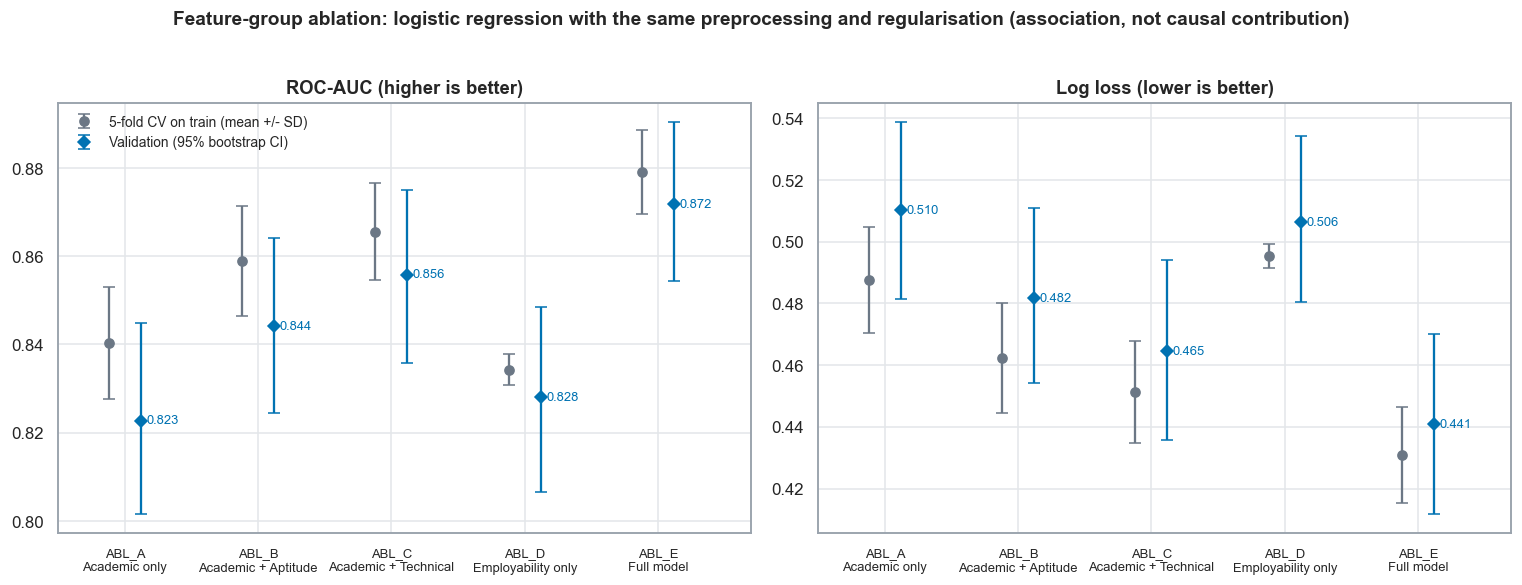

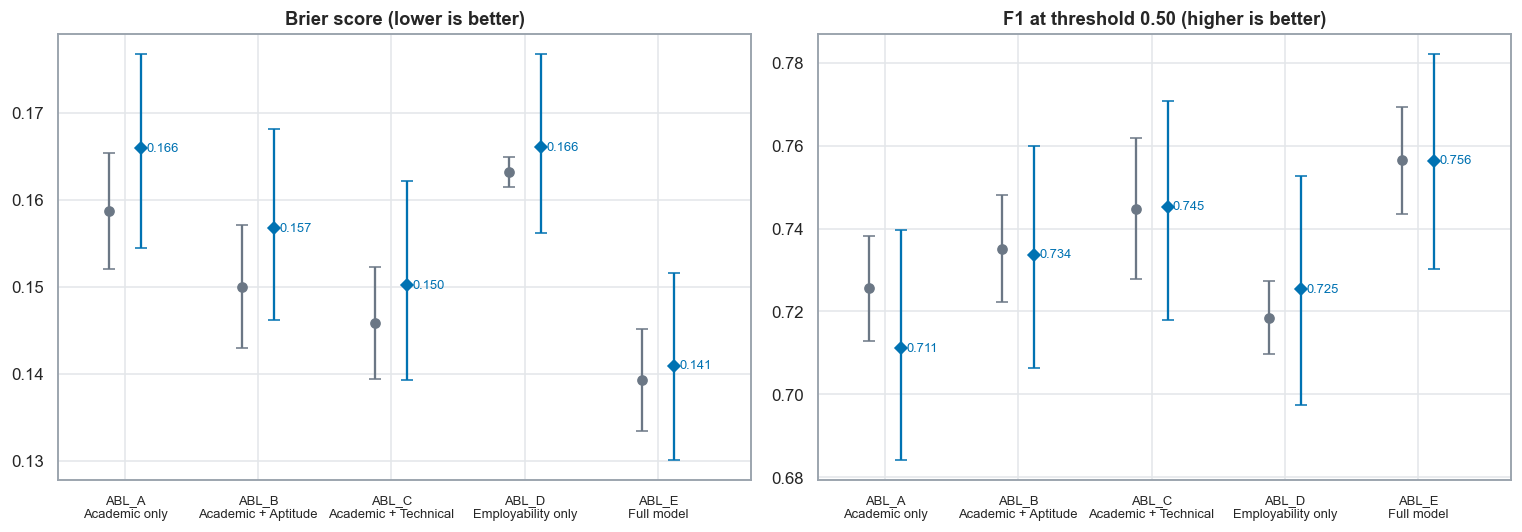

In [17]:
order = list(GROUPS); xs = np.arange(len(order)); lab = [f"{g}\n{GROUPS[g][0]}" for g in order]
def abl_panel(ax, m, ttl, better):
    cvm, cvs = abl[f"cv_{m}_mean"].to_numpy(), abl[f"cv_{m}_sd"].to_numpy(); v = abl[f"val_{m}"].to_numpy()
    lo, hi = abl[f"val_{m}_ci_lo"].to_numpy(), abl[f"val_{m}_ci_hi"].to_numpy()
    ax.errorbar(xs - 0.12, cvm, yerr=cvs, fmt="o", color=NEUTRAL, capsize=4, ms=6, label="5-fold CV on train (mean +/- SD)")
    ax.errorbar(xs + 0.12, v, yerr=[v - lo, hi - v], fmt="D", color=LR_C, capsize=4, ms=6, label="Validation (95% bootstrap CI)")
    for x, a in zip(xs, v): ax.text(x + 0.16, a, f"{a:.3f}", fontsize=8.5, va="center", ha="left", color=LR_C)
    ax.set_xticks(xs); ax.set_xticklabels(lab, fontsize=8.5); ax.set_title(f"{ttl} ({better})"); ax.set_xlim(-0.5, len(order) - 0.3)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2)); abl_panel(axes[0], "roc_auc", "ROC-AUC", "higher is better"); abl_panel(axes[1], "log_loss", "Log loss", "lower is better")
axes[0].legend(frameon=False, fontsize=9, loc="upper left")
fig.suptitle("Feature-group ablation: logistic regression with the same preprocessing and regularisation (association, not causal contribution)", y=1.02, fontsize=12.5, fontweight="semibold")
savefig(fig, "phase6_feature_ablation")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.0)); abl_panel(axes[0], "brier", "Brier score", "lower is better"); abl_panel(axes[1], "f1", "F1 at threshold 0.50", "higher is better")
savefig(fig, "phase6_feature_ablation_brier_f1")

# PART E - Error analysis (validation, `LR_B`)
Primary classification threshold **0.50**; **high-confidence** is pre-declared as `p >= 0.80` (predicts Placed) or `p <= 0.20` (predicts NotPlaced), matching the Phase 5 bands. Groups: false positives / false negatives (any confidence), correct high-confidence predictions, and the instructive **incorrect high-confidence** groups (HC false positives: predicted >= 0.80 but NotPlaced; HC false negatives: predicted <= 0.20 but Placed). Group sizes are small for the high-confidence errors, so feature patterns are reported descriptively with standardised differences and **no significance tests**.

In [18]:
va = X_va.copy(); va["p"] = p_va; va["y"] = y_va
masks = {"TP (predicted Placed, Placed)": (p_va >= .5) & (y_va == 1), "TN (predicted NotPlaced, NotPlaced)": (p_va < .5) & (y_va == 0),
         "FP (predicted Placed, NotPlaced)": (p_va >= .5) & (y_va == 0), "FN (predicted NotPlaced, Placed)": (p_va < .5) & (y_va == 1),
         "HC_TP: p >= 0.80, Placed": (p_va >= .8) & (y_va == 1), "HC_TN: p <= 0.20, NotPlaced": (p_va <= .2) & (y_va == 0),
         "HC_FP: p >= 0.80, NotPlaced": (p_va >= .8) & (y_va == 0), "HC_FN: p <= 0.20, Placed": (p_va <= .2) & (y_va == 1)}
masks["HC_correct (HC_TP + HC_TN)"] = masks["HC_TP: p >= 0.80, Placed"] | masks["HC_TN: p <= 0.20, NotPlaced"]
masks["HC_incorrect (HC_FP + HC_FN)"] = masks["HC_FP: p >= 0.80, NotPlaced"] | masks["HC_FN: p <= 0.20, Placed"]
n_err, N = int(masks["FP (predicted Placed, NotPlaced)"].sum() + masks["FN (predicted NotPlaced, Placed)"].sum()), len(va)
rows = []
for g, m in masks.items():
    s = va[m]; r = {"group": g, "n": int(m.sum()), "pct_of_validation": 100 * m.mean(), "pct_of_all_errors": 100 * m.sum() / n_err if g.startswith(("FP", "FN", "HC_FP", "HC_FN", "HC_incorrect")) else np.nan,
                    "p_min": s.p.min(), "p_q25": s.p.quantile(.25), "p_median": s.p.median(), "p_q75": s.p.quantile(.75), "p_max": s.p.max()}
    for f in CONT + COUNT: r[f"mean_{f}"] = s[f].mean()
    for f in BIN: r[f"pct_{f}_Yes"] = 100 * (s[f] == "Yes").mean()
    rows.append(r)
err = pd.DataFrame(rows); err.to_csv(MET / "07_error_analysis.csv", index=False)
display(err.set_index("group").round(2).T)

group,"TP (predicted Placed, Placed)","TN (predicted NotPlaced, NotPlaced)","FP (predicted Placed, NotPlaced)","FN (predicted NotPlaced, Placed)","HC_TP: p >= 0.80, Placed","HC_TN: p <= 0.20, NotPlaced","HC_FP: p >= 0.80, NotPlaced","HC_FN: p <= 0.20, Placed",HC_correct (HC_TP + HC_TN),HC_incorrect (HC_FP + HC_FN)
n,458.00,734.00,135.00,160.00,249.00,524.00,28.00,60.00,773.00,88.00
pct_of_validation,30.80,49.36,9.08,10.76,16.75,35.24,1.88,4.03,51.98,5.92
pct_of_all_errors,NaN,NaN,45.76,54.24,NaN,NaN,9.49,20.34,NaN,29.83
p_min,0.50,0.00,0.50,0.02,0.80,0.00,0.80,0.02,0.00,0.02
p_q25,0.71,0.05,0.59,0.13,0.85,0.03,0.82,0.07,0.05,0.09
p_median,0.82,0.11,0.67,0.26,0.89,0.07,0.84,0.11,0.12,0.15
p_q75,0.90,0.23,0.78,0.40,0.91,0.12,0.88,0.15,0.85,0.82
p_max,0.95,0.50,0.93,0.50,0.95,0.20,0.93,0.20,0.95,0.93
mean_CGPA,8.17,7.37,8.02,7.48,8.27,7.28,8.26,7.27,7.60,7.59
mean_AptitudeTestScore,86.66,74.22,84.41,77.36,88.78,72.26,87.57,74.83,77.58,78.89


In [19]:
# Standardised differences between each error group and its correctly classified comparator on the same predicted side (numeric encoding of all 10 features)
num = va[FEATURES].copy()
for f in BIN: num[f] = (num[f] == "Yes").astype(int)
def smd(a, b):
    sa, sb = a.std(ddof=1), b.std(ddof=1); sp = np.sqrt((sa ** 2 + sb ** 2) / 2); return (a.mean() - b.mean()) / sp if sp > 0 else np.nan
CMP = [("HC_FP vs HC_TP", "HC_FP: p >= 0.80, NotPlaced", "HC_TP: p >= 0.80, Placed"), ("HC_FN vs HC_TN", "HC_FN: p <= 0.20, Placed", "HC_TN: p <= 0.20, NotPlaced"),
       ("FP vs TP", "FP (predicted Placed, NotPlaced)", "TP (predicted Placed, Placed)"), ("FN vs TN", "FN (predicted NotPlaced, Placed)", "TN (predicted NotPlaced, NotPlaced)")]
srows = []
for nm, a, b in CMP:
    for f in FEATURES:
        srows.append({"comparison": nm, "n_error_group": int(masks[a].sum()), "n_comparator": int(masks[b].sum()), "feature": f,
                      "mean_error_group": num.loc[masks[a], f].mean(), "mean_comparator": num.loc[masks[b], f].mean(), "standardised_difference": smd(num.loc[masks[a], f], num.loc[masks[b], f])})
smd_df = pd.DataFrame(srows); smd_df.to_csv(MET / "07_error_feature_comparison.csv", index=False)
piv = smd_df.pivot(index="feature", columns="comparison", values="standardised_difference").reindex(FEATURES)[[c[0] for c in CMP]]
print("Standardised mean difference (error group minus comparator; |d| < 0.2 small, ~0.5 medium, >= 0.8 large). n:", {nm: (int(masks[a].sum()), int(masks[b].sum())) for nm, a, b in CMP})
display(piv.round(2))

# Ceiling statistics: how wrong should a perfectly calibrated model be? (expected error = mean(min(p, 1-p)))
exp_err, obs_err = float(np.minimum(p_va, 1 - p_va).mean()), float(((p_va >= .5) != (y_va == 1)).mean())
hc_hi, hc_lo = p_va >= .8, p_va <= .2
ceiling = pd.DataFrame([
    {"quantity": "observed error rate at 0.50 (validation)", "value": obs_err},
    {"quantity": "expected error rate if probabilities were perfectly calibrated: mean(min(p, 1-p))", "value": exp_err},
    {"quantity": "n in high band (p >= 0.80)", "value": int(hc_hi.sum())}, {"quantity": "observed NotPlaced share in high band (error rate there)", "value": float(1 - y_va[hc_hi].mean())},
    {"quantity": "expected error in high band if calibrated: mean(1-p)", "value": float((1 - p_va[hc_hi]).mean())},
    {"quantity": "n in low band (p <= 0.20)", "value": int(hc_lo.sum())}, {"quantity": "observed Placed share in low band (error rate there)", "value": float(y_va[hc_lo].mean())},
    {"quantity": "expected error in low band if calibrated: mean(p)", "value": float(p_va[hc_lo].mean())},
    {"quantity": "share of validation students with 0.2 < p < 0.8", "value": float(((p_va > .2) & (p_va < .8)).mean())},
    {"quantity": "share of all errors that fall in 0.2 < p < 0.8", "value": float((((p_va >= .5) != (y_va == 1)) & (p_va > .2) & (p_va < .8)).sum() / max(1, ((p_va >= .5) != (y_va == 1)).sum()))}])
bins_ = np.linspace(0, 1, 26); h1, _ = np.histogram(p_va[y_va == 1], bins_, density=False); h0, _ = np.histogram(p_va[y_va == 0], bins_, density=False)
ceiling = pd.concat([ceiling, pd.DataFrame([{"quantity": "overlap coefficient of predicted-probability distributions, Placed vs NotPlaced (25 bins; 1 = identical)", "value": float(np.minimum(h1 / h1.sum(), h0 / h0.sum()).sum())}])], ignore_index=True)
ceiling.to_csv(MET / "07_error_ceiling.csv", index=False); display(ceiling.round(4))

Standardised mean difference (error group minus comparator; |d| < 0.2 small, ~0.5 medium, >= 0.8 large). n: {'HC_FP vs HC_TP': (28, 249), 'HC_FN vs HC_TN': (60, 524), 'FP vs TP': (135, 458), 'FN vs TN': (160, 734)}


comparison,HC_FP vs HC_TP,HC_FN vs HC_TN,FP vs TP,FN vs TN
feature,,,,
CGPA,-0.05,-0.01,-0.33,0.18
Internships,-0.29,0.14,-0.13,0.18
Projects,-0.05,0.36,-0.32,0.43
Workshops/Certifications,-0.33,-0.09,-0.30,0.20
AptitudeTestScore,-0.44,0.46,-0.50,0.51
SoftSkillsRating,-0.22,0.14,-0.43,0.31
ExtracurricularActivities,-0.15,0.52,-0.26,0.61
PlacementTraining,0.13,0.14,-0.30,0.30
SSC_Marks,-0.32,0.00,-0.14,0.32


,quantity,value
0,observed error rate at 0.50 (validation),0.1984
1,"expected error rate if probabilities were perfectly calibrated: mean(min(p, 1-p))",0.1962
2,n in high band (p >= 0.80),277.0000
3,observed NotPlaced share in high band (error rate there),0.1011
4,expected error in high band if calibrated: mean(1-p),0.1215
5,n in low band (p <= 0.20),584.0000
6,observed Placed share in low band (error rate there),0.1027
7,expected error in low band if calibrated: mean(p),0.0834
8,share of validation students with 0.2 < p < 0.8,0.4210
9,share of all errors that fall in 0.2 < p < 0.8,0.7017


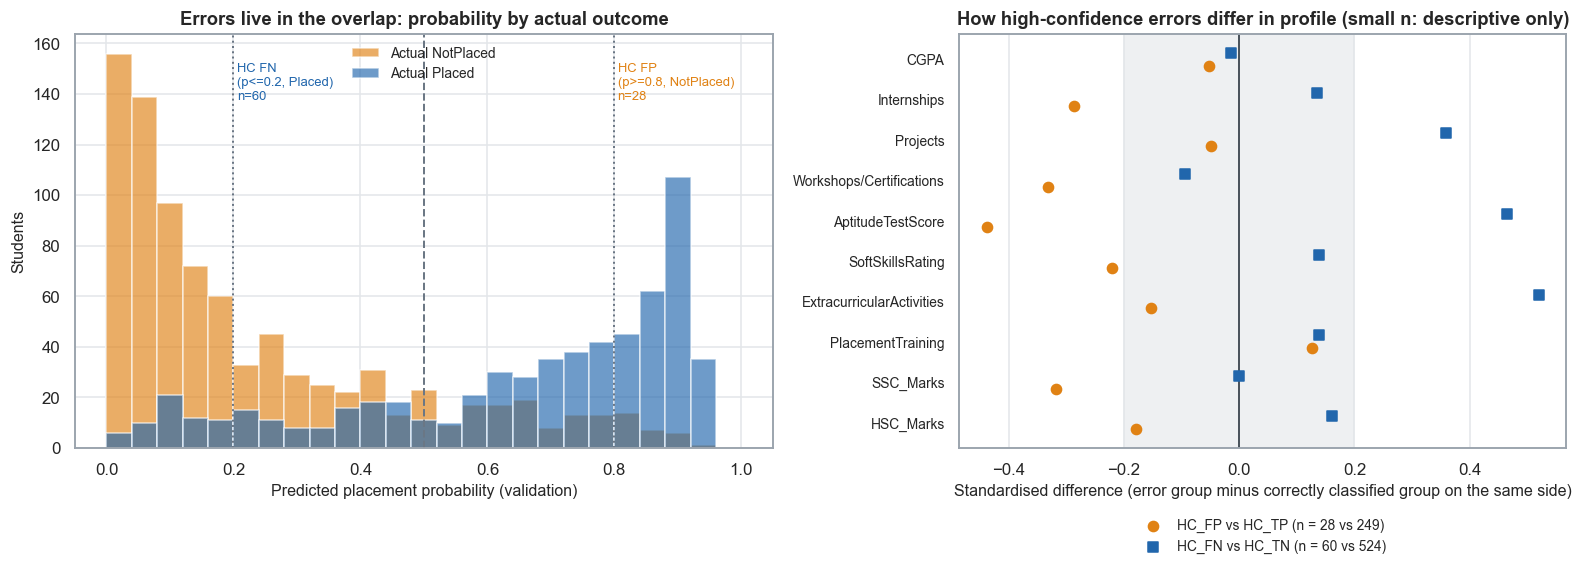

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.4), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]; B_ = np.linspace(0, 1, 26)
ax.hist(p_va[y_va == 0], bins=B_, color=NOT_C, alpha=0.65, label="Actual NotPlaced"); ax.hist(p_va[y_va == 1], bins=B_, color=PLACED_C, alpha=0.65, label="Actual Placed")
for v in (0.2, 0.5, 0.8): ax.axvline(v, color=NEUTRAL, ls="--" if v == 0.5 else ":", lw=1.3)
ax.set_xlabel("Predicted placement probability (validation)"); ax.set_ylabel("Students")
ax.text(0.205, ax.get_ylim()[1] * 0.93, f"HC FN\n(p<=0.2, Placed)\nn={masks['HC_FN: p <= 0.20, Placed'].sum()}", fontsize=8.5, va="top", color=PLACED_C)
ax.text(0.805, ax.get_ylim()[1] * 0.93, f"HC FP\n(p>=0.8, NotPlaced)\nn={masks['HC_FP: p >= 0.80, NotPlaced'].sum()}", fontsize=8.5, va="top", color=NOT_C)
ax.set_title("Errors live in the overlap: probability by actual outcome"); ax.legend(frameon=False, loc="upper center", fontsize=9)
ax = axes[1]; yy = np.arange(len(FEATURES))[::-1]
cmp_n = {nm: (int(masks[a].sum()), int(masks[b].sum())) for nm, a, b in CMP}
for off, (nm, c, mk) in zip((-0.16, 0.16), [("HC_FP vs HC_TP", NOT_C, "o"), ("HC_FN vs HC_TN", PLACED_C, "s")]):
    ax.scatter(piv[nm].reindex(FEATURES), yy + off, color=c, marker=mk, s=44, label=f"{nm} (n = {cmp_n[nm][0]} vs {cmp_n[nm][1]})", zorder=3)
ax.axvline(0, color="#1d2733", lw=1); ax.axvspan(-0.2, 0.2, color="#e3e6ea", alpha=0.6, zorder=0)
ax.set_yticks(yy); ax.set_yticklabels(FEATURES, fontsize=9); ax.set_xlabel("Standardised difference (error group minus correctly classified group on the same side)")
ax.set_title("How high-confidence errors differ in profile (small n: descriptive only)"); ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=1); ax.grid(axis="y", visible=False)
savefig(fig, "phase6_error_analysis")

# PART F - Does the dataset's structure limit predictive performance?
Evidence already established in Phases 1-3 (not re-derived here), read together with the results above:
- **Step-like and non-monotonic count variables.** Placement rates for Internships (33% / 33% / 69%), Workshops (28% / 21% / 73% / 56%) and Projects (60% with n = 30, 17%, 31%, 71%) are not smooth trends; they are steps that persist after stratifying on aptitude (Phase 3).
- **Bounded scores with hard floors and ceilings** (CGPA 6.5, aptitude 90, soft skills 4.8, SSC 55) and **very large, systematic effects across every predictor**.
- **Heavy overlap between classes** despite high AUC (Phase 4/5; see the overlap coefficient and the mid-probability error share in Part E) and **8 conflicting-label profiles** (16 rows; identical predictors, different outcome) concentrated in the top profile region, i.e. a label that depends on something the features do not capture, or noise.
- Logistic regression, gradient boosting and random forest are **practically tied** (Phase 4/5), so flexible models do not extract extra signal from interactions or steps beyond what categorical counts already supply.

The observed structure is **consistent with a rule-based or constructed dataset** (the dataset card gives no provenance, and nothing here establishes how the data were generated). If so, the attainable accuracy is bounded by the generating rule plus label noise, and model performance here should **not** be generalised automatically to real university placement populations, other campuses or other years.

## Phase 6 conclusions

> **Evidence labels.** *OOF* = Phase 5 out-of-fold training predictions (n = 6,938). *Validation* = the development validation split (n = 1,487; observed placement rate 41.6%), which already informed model selection in Phase 4, so validation results at a threshold chosen on validation are **optimistic**. *CV* = 5-fold stratified cross-validation on the training set (the Phase 5 folds). **`test.csv` was never opened** (a hook raises an error on any attempt; the audit above lists every data file read). Everything describes **associations learned by the fitted model** in observational, possibly rule-generated data; nothing here is a causal claim. The model is still the *provisional* raw (uncalibrated) `LR_B`; no final model is declared.

### A. Decision threshold
**Criterion (fixed in advance).** *Selected operating threshold under the F1-oriented criterion* = the threshold on the 0.20-0.80 grid (step 0.05) with the highest **validation** F1; ties go to the value closest to 0.50. Result: **0.35** (validation F1 0.766). It is not called "best": F1 weights precision and recall equally and ignores the costs of the two error types, which the project has not defined.

| Validation (n = 1,487) | Threshold | Accuracy | Precision | Recall | Specificity | F1 | FP / FN | Predicted placed |
|---|---|---|---|---|---|---|---|---|
| Lower | 0.30 | 0.774 | 0.681 | 0.859 | 0.713 | 0.760 | 249 / 87 | 52.5% |
| **Selected** | **0.35** | 0.787 | 0.705 | 0.838 | 0.750 | **0.766** | 217 / 100 | 49.4% |
| Default | 0.50 | 0.802 | 0.772 | 0.741 | 0.845 | 0.756 | 135 / 160 | 39.9% |
| Higher | 0.70 | 0.777 | 0.850 | 0.561 | 0.930 | 0.676 | 61 / 271 | 27.4% |

- **The choice between 0.35 and 0.50 matters little for F1.** Validation F1 is within 0.01 of its maximum for every threshold from 0.30 to 0.55 (0.760, 0.766, 0.764, 0.764, 0.756, 0.757). The paired-bootstrap difference F1(0.35) - F1(0.50) is +0.010 (95% interval -0.007 to +0.028), which includes 0, so **0.50 is practically tied with the selected threshold**. On the independent OOF data the F1-optimal threshold is 0.40 (F1 0.763); at 0.35 F1 is 0.762 against 0.756 at 0.50, and 0.35 is better in 4 of the 5 folds (mean +0.006). So the selection sits on a flat plateau (about 0.35-0.45), not on a sharp optimum.
- **What the threshold really trades.** Lowering it from 0.50 to 0.35 converts 60 false negatives into 82 extra false positives on validation: recall rises from 0.74 to 0.84, precision falls from 0.77 to 0.71, accuracy falls from 0.802 to 0.787 (accuracy itself is highest at 0.55-0.60, 0.807 / 0.802), and the model labels 49% of students "Placed" against a true rate of 42%. The sensibility check passed (precision and recall both >= 0.60; predicted rate within 10 points of the observed rate). Thresholds above 0.65 give up too much recall for the precision gained (F1 falls to 0.72 and below).
- **A threshold is a policy choice, not a model property.** If a false "likely to be placed" is costlier than a missed one (or vice versa), the right threshold moves, and 0.35, 0.40 and 0.50 are all defensible. The probability, not the label, remains the primary output.

### B. Logistic-regression coefficients (associations, not causal effects)
Odds ratios are per one training SD for the five standardised scores and relative to the stated reference for the one-hot variables. 95% intervals are Wald intervals from an **unpenalised** fit on the same design; the penalised and unpenalised coefficients agree to within 0.006 log-odds everywhere except `Projects = 0`, which the L2 penalty pulls toward 0 (0.50 vs 0.67) because it has only 19 training students.

| Feature (reference) | Odds ratio (95% interval) | Reading |
|---|---|---|
| PlacementTraining = Yes (No) | 2.75 (2.33-3.28) | largest single coefficient; associated with higher predicted odds |
| ExtracurricularActivities = Yes (No) | 1.95 (1.66-2.28) | associated with higher predicted odds |
| AptitudeTestScore (per 1 SD) | 1.65 (1.51-1.81) | largest of the standardised scores |
| SSC_Marks / SoftSkillsRating / CGPA / HSC_Marks (per 1 SD) | 1.33 / 1.32 / 1.29 / 1.23 | each about 1.2-1.3 |
| Workshops = 2 vs 0 | 1.53 (1.30-1.80) | |
| Workshops = 1 vs 0 | 0.73 (0.61-0.86) | level 1 is *below* level 0, as found in Phases 2-3 |
| Workshops = 3 vs 0 | 0.99 (0.71-1.39) | about equal to 0 (n = 208) |
| Projects = 1 / 2 vs 3 | 0.66 (0.55-0.79) / 0.73 (0.61-0.86) | fewer than 3 projects is associated with lower odds than 3 |
| Projects = 0 vs 3 | 1.65 (0.63-6.04) | **unreliable: 19 students; interval includes 1; do not interpret** |
| Internships = 0 / 2 vs 1 | 1.26 (1.06-1.49) / 1.25 (1.07-1.48) | level 1 is slightly lower than both 0 and 2; effect is small |

- The two binary variables and aptitude carry the largest associations. The count variables remain non-monotonic after adjustment (Workshops 1 < 0, Projects 1 and 2 < 3), which supports the Phase 4 choice of treating them as categories.
- Internships has a small coefficient once the other variables are included, and (below) almost no predictive importance, in contrast with its strong raw association in the EDA, which suggests that raw association overlaps with that of the other predictors (this is an inference from the model, not tested directly).
- These are conditional, in-sample associations from one model and one representation; the intervals ignore that representation and reference levels were chosen with the data in view.

### C. Permutation importance and global comparison (validation)
Shuffling each raw column in the full pipeline (20 repeats, seed 42) gives the AUC lost (baseline validation AUC 0.872) and the log loss added (baseline 0.441):

| Rank | Feature | AUC lost (mean +/- SD) | Log loss added |
|---|---|---|---|
| 1 | AptitudeTestScore | 0.0208 +/- 0.0036 | 0.0333 |
| 2 | PlacementTraining | 0.0177 +/- 0.0043 | 0.0267 |
| 3 | ExtracurricularActivities | 0.0125 +/- 0.0022 | 0.0189 |
| 4 | Workshops/Certifications | 0.0081 +/- 0.0015 | 0.0136 |
| 5 | SoftSkillsRating | 0.0060 +/- 0.0015 | 0.0098 |
| 6 | SSC_Marks | 0.0050 +/- 0.0019 | 0.0087 |
| 7 | Projects | 0.0039 +/- 0.0011 | 0.0069 |
| 8 | HSC_Marks | 0.0038 +/- 0.0016 | 0.0064 |
| 9 | CGPA | 0.0036 +/- 0.0013 | 0.0064 |
| 10 | Internships | 0.0003 +/- 0.0006 | 0.0006 |

- **Consistent across methods:** aptitude, placement training and extracurricular activities are the three most influential features under permutation importance (AUC and log loss agree on ranks 1-7 and 10) and under the SD of each feature's contribution to the linear predictor (Spearman rank correlation 0.92 over only 10 features, a rough guide). Internships is last in both.
- **Where they differ.** SSC_Marks is 4th by contribution SD but 6th by permutation importance; Projects is 9th by contribution SD but 7th by permutation; CGPA is 7th vs 9th. These are small shifts among features with similar sizes.
- **Why importance is shared and unstable.** The five scores are moderately correlated (aptitude with HSC r = 0.56, with Projects 0.54, soft skills 0.51, SSC 0.51), so shuffling one column removes only the part of its information that the others do not duplicate; the single-feature values are therefore not exclusive contributions, and ranks 5-9 (AUC loss 0.0036-0.0060, SDs 0.0013-0.0019) are close enough that their order should not be over-read. There is no single "true" ranking.
- Importance describes what the **fitted model relies on to predict**, not what would change an outcome.

### D. Individual validation-student explanations
Contributions are `coefficient x transformed value`, summed per feature, relative to the training mean / reference level; each case's contributions plus the intercept (-1.69) reproduce the model's log-odds exactly.

| Case | Actual | p | Class at 0.50 / 0.35 | Main positive | Main negative |
|---|---|---|---|---|---|
| 1 Very high | Placed | 0.91 | Placed / Placed | Placement training +1.01, extracurricular +0.67, aptitude 87 (+0.47) | none |
| 2 Very low | NotPlaced | 0.02 | NotPlaced / NotPlaced | CGPA 8.0 (+0.12) | aptitude 69 (-0.63), soft skills 3.6 (-0.49), Projects = 1 (-0.41) |
| 3 Boundary | Placed | 0.50 | Placed / Placed | placement training +1.01, extracurricular +0.67, HSC 88 (+0.32) | Projects = 1 (-0.41), aptitude 76 (-0.20) |
| 4 False positive (most confident) | NotPlaced | 0.93 | Placed / Placed | training +1.01, extracurricular +0.67, aptitude 90 (+0.65) | none |
| 5 False negative (most confident) | Placed | 0.02 | NotPlaced / NotPlaced | none | soft skills 3.6 (-0.49), CGPA 6.6 (-0.44), Projects = 1 (-0.41) |
| 6 Middle | NotPlaced | 0.34 | NotPlaced / NotPlaced | placement training +1.01, SSC 83 (+0.38), soft skills 4.8 (+0.32) | Projects = 2 (-0.32), Workshops = 1 (-0.31) |

- The explanations are additive and readable: the model's very confident cases are decided by the same few features that dominate globally (training, extracurricular, aptitude, then the count levels).
- **The most confident false positive (case 4) has essentially the top profile** (CGPA 8.6, 2 internships, 3 projects, 2 workshops, aptitude 90, soft skills 4.8, training and extracurricular both Yes, SSC 80, HSC 85) and is almost indistinguishable from the correctly-predicted case 1. This matches the Phase 2 finding of 8 conflicting-label profiles in the same top region (identical predictors, different outcomes): the features carry no information that could separate such students. Cases 4 and 5 are deliberately the *most extreme* errors, not typical ones.

### E. Feature-group ablation (logistic regression, same preprocessing and regularisation)
`ABL_E` reproduces the Phase 4 `LR_B` validation probabilities and the Phase 5 OOF probabilities exactly (asserted).

| Group | Features | CV AUC (mean +/- SD) | CV log loss | Val AUC (95% CI) | Val log loss | Val Brier | Val F1 @ 0.50 |
|---|---|---|---|---|---|---|---|
| ABL_A Academic | 3 | 0.840 +/- 0.013 | 0.488 | 0.823 (0.802-0.845) | 0.510 | 0.166 | 0.711 |
| ABL_B + Aptitude | 4 | 0.859 +/- 0.013 | 0.462 | 0.844 (0.825-0.864) | 0.482 | 0.157 | 0.734 |
| ABL_C + Technical | 7 | 0.866 +/- 0.011 | 0.451 | 0.856 (0.836-0.875) | 0.465 | 0.150 | 0.745 |
| ABL_D Employability only | 3 | 0.834 +/- 0.004 | 0.496 | 0.828 (0.807-0.849) | 0.507 | 0.166 | 0.725 |
| ABL_E Full | 10 | 0.879 +/- 0.010 | 0.431 | 0.872 (0.854-0.890) | 0.441 | 0.141 | 0.756 |

Reference (always predict the train rate): AUC 0.500, log loss 0.679, Brier 0.243.

| Step (bigger minus smaller) | Validation dAUC (95% CI) | Validation d log loss (95% CI) | CV folds improved (AUC / log loss) |
|---|---|---|---|
| Aptitude added to academic (B - A) | +0.021 (0.013-0.030) | -0.029 (-0.040 to -0.018) | 5/5, 5/5 |
| Technical counts added to B (C - B) | +0.012 (0.006-0.018) | -0.017 (-0.025 to -0.009) | 5/5, 5/5 |
| Employability added to C (E - C) | +0.016 (0.008-0.023) | -0.024 (-0.035 to -0.013) | 5/5, 5/5 |
| Full vs academic only (E - A) | +0.049 (0.037-0.061) | -0.070 (-0.087 to -0.053) | 5/5, 5/5 |
| Full vs employability only (E - D) | +0.044 (0.029-0.058) | -0.066 (-0.083 to -0.046) | 5/5, 5/5 |

- **Academic information alone** (CGPA, SSC, HSC) already gives validation AUC 0.82 and log loss 0.51, well above the 0.50 / 0.68 reference.
- **Employability alone** (soft skills, extracurricular, placement training; only 3 features) is as informative as academic alone (AUC 0.828 vs 0.823, log loss 0.507 vs 0.510).
- **Each added group improved predictive performance** on top of what was already included (aptitude +0.021 AUC, technical counts +0.012, employability +0.016), consistently in all 5 folds and with validation intervals excluding 0. No group is redundant, and none dominates: the full model improves on academic-only by 0.049 AUC and 0.070 log loss.
- **Cautions.** The groups overlap and are correlated, so these increments are order-dependent (employability's gain is measured only after everything else; aptitude's after academic only), not clean contributions of each group. The increments are modest, and the CV SDs (about 0.011-0.013 AUC) show that the smaller steps (about 0.012) are of the same size as fold-to-fold variation, although they are consistent in sign. Validation intervals of the individual models overlap widely; only the paired differences carry the evidence.

### F. Error analysis (validation, `LR_B`, threshold 0.50)
- **Overall.** 295 errors: 135 false positives (9.1% of students) and 160 false negatives (10.8%). The observed error rate (19.8%) equals the error rate expected **if the probabilities were perfectly calibrated** (mean of min(p, 1-p) = 19.6%): the model errs about as often as its own probabilities say it should, so the errors are mostly irreducible uncertainty given these ten features, not a calibration failure.
- **Where the errors are.** 70% of all errors fall among the 42% of students with 0.2 < p < 0.8. The predicted-probability distributions of Placed and NotPlaced overlap substantially (overlap coefficient 0.39).
- **High-confidence (p >= 0.8 or <= 0.2) correct predictions:** 773 students (52.0%).
- **High-confidence incorrect predictions: 88 students (5.9% of students; 29.8% of all errors).**
  - *HC false positives* (p >= 0.80 but NotPlaced): **28 students** (1.9%; 9.5% of errors); within the high band the NotPlaced share is 10.1% against 12.2% expected. Their profile is close to the correctly predicted high-confidence Placed students (all standardised differences |d| <= 0.44; 100% have placement training and 96% extracurricular activities). Nothing in the recorded features distinguishes them.
  - *HC false negatives* (p <= 0.20 but Placed): **60 students** (4.0%; 20.3% of errors); within the low band the Placed share is 10.3% against 8.3% expected. Compared with other low-probability students they have more extracurricular activity (38% vs 16%; d = 0.52), higher aptitude (d = 0.46) and more projects (d = 0.36), i.e. they sit somewhat higher in the profile range than the typical low-probability student but still below 0.2.
- **Practical ceiling.** About 20% error at the default threshold, and roughly 1 in 10 confident predictions wrong in both bands, appears to be the limit of what these ten features support in this dataset, consistent with the 8 conflicting-label profiles (Phase 2) and the model-family tie (Phase 4-5). Small groups (28 and 60 students): the feature patterns are descriptive only.

### G. Does the dataset structure limit what a model can achieve?
The observed structure is **consistent with a rule-based or constructed dataset**: strong, step-like and non-monotonic count effects (Internships, Workshops, Projects), hard floors and ceilings on the scores, very large systematic effects across all predictors, heavy class overlap with a performance plateau shared by logistic regression, boosting and forest, and conflicting labels at the top of the profile range. The dataset card gives no provenance, so this is **not** established, and nothing here proves the data are synthetic. If a rule plus label noise generated the data, the attainable accuracy is bounded by that process, and **results should not be generalised automatically to real university placement populations, other campuses or other years**; the coefficients are descriptive of this dataset, not of how placement works.

### H. Should the provisional model remain?
**Yes: logistic regression with categorical counts (`LR_B`, raw probabilities) remains the provisional model, still not final.** Phase 6 adds interpretability and error evidence but changes none of the Phase 4-5 conclusions: the coefficients are readable and sensible, the explanations are additive and exact, the full 10-feature model beats every partial group, the errors match the model's own stated uncertainty, and no calibration step is needed. The only new operational item is the threshold, which is a policy choice with a flat F1 plateau.

### I. Recommendation for Phase 7
1. **Fix the evaluation protocol before opening `test.csv`:** freeze `LR_B` (Phase 4 pipeline, C = 1, raw probabilities, fitted on the training set only), the operating threshold(s) to report (the default 0.50 and the F1-oriented 0.35, both declared in advance), and the metric list (ROC-AUC, log loss, Brier, calibration slope / intercept / reliability, and precision / recall / F1 at the declared thresholds with bootstrap intervals). GB_B and RF_B may be reported as pre-declared secondary comparators with no re-selection.
2. **Open the test set exactly once**, with the same audit hook, and report the result whatever it is.
3. Decide in advance whether to refit on train + validation for any deployment artifact; this must not change the reported test result.
4. Subgroup and stability checks (small count levels, top-profile region) can be added as clearly labelled exploratory analyses on train/validation only.

### Limitations
- Validation was already used for model development, so validation figures for the chosen threshold and for the already-selected model are optimistic; the OOF analysis is the independent check.
- Coefficient intervals are Wald intervals for the unpenalised fit, conditional on the representation and reference levels; permutation importance is not additive in the presence of correlated predictors.
- Ablation groups overlap and are order-dependent; five CV folds give coarse stability evidence; the validation bootstrap treats students as independent.
- The high-confidence error groups are small (28 and 60 students); the individual cases were chosen by fixed rules (two are deliberately the most extreme errors).
- One possibly rule-generated dataset; no real-world generalisation claim is made.

## Test-set audit

In [21]:
data_ext = (".csv", ".parquet", ".json", ".joblib", ".pkl", ".feather", ".xlsx")
opened = sorted({os.path.normpath(p) for p in _OPENED if p.lower().endswith(data_ext)})
print("Data files opened during this notebook run:")
for p in opened: print("  ", p)
names_ = [os.path.basename(p).lower() for p in opened]
assert "test.csv" not in names_, "test.csv (processed or raw) was opened!"
assert not any(("raw" in Path(p).parts and "data" in Path(p).parts) for p in opened), "a raw data file was opened"
assert "modeling_dataset.csv" not in names_ and "campus_recruitment_combined_flagged.csv" not in names_
assert {"train.csv", "validation.csv"} <= set(names_)
assert "X_test" not in globals() and "y_test" not in globals() and "test" not in globals()
print("\nASSERTIONS PASSED: test.csv (raw or processed) was never opened. Threshold analysis used Phase 5 OOF + validation predictions; explanations, permutation importance and error analysis used validation; ablation used train CV + one validation evaluation.")

Data files opened during this notebook run:
   C:\Users\Aryan\.matplotlib\fontlist-v390.json
   C:\Users\Aryan\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy-2.4.2.dist-info\direct_url.json
   D:\Student-Placement-Prediction\student-placement-prediction\data\processed\train.csv
   D:\Student-Placement-Prediction\student-placement-prediction\data\processed\validation.csv
   D:\Student-Placement-Prediction\student-placement-prediction\models\phase4\LR_B.joblib
   D:\Student-Placement-Prediction\student-placement-prediction\models\phase4\model_configs.json
   D:\Student-Placement-Prediction\student-placement-prediction\results\metrics\modeling\05_logistic_coefficients.csv
   D:\Student-Placement-Prediction\student-placement-prediction\results\metrics\modeling\05_validation_predictions.csv
   D:\Student-Placement-Prediction\student-placement-prediction\results\metrics\modeling\06_oof_predictions.csv
   D:\Student-Placement-Prediction\student-placement-prediction\results\me